# Yemen-CropWatch — دفتر المناقشة الجامعية والتنفيذ النهائي

**المشروع:** تصنيف إشارات الغطاء النباتي الزراعي من سلاسل Sentinel‑2 الشهرية في منطقة pilot بمحافظة ذمار، اليمن.

**النموذج المختار:** NASA Harvest Presto (Frozen Encoder) + MLP Classifier.

**هدف الدفتر:** شرح بنية المشروع، تتبع البيانات والـTensor، توضيح التدريب والتسميات وConfusion Matrix، تقييم التعميم المكاني، ثم إعادة تدريب رأس التصنيف بالإعدادات المختارة وحفظه وتجهيز نقطة ربط مع موقع ويب.

> **حدود علمية يجب قولها في المناقشة:** الفئات المستخدمة هي Proxy Labels مشتقة من `source_class` وليست Ground Truth ميدانية مستقلة. نتائج Outer Validation استُخدمت سابقًا أثناء تطوير المشروع؛ لذلك هي نتائج تطوير مكاني وليست اختبارًا خارجيًا مستقلاً. لا يوجد في هذا الدفتر ادعاء بأن النموذج يحقق دقة ميدانية مثبتة.

---

## خريطة التقييم في المناقشة

| الوزن | المحور | ما يجب أن تثبته |
|---:|---|---|
| 20% | CNN وTensor Dimensions | الفرق بين Temporal CNN والمسار النهائي Presto، وأبعاد الإدخال والخرج |
| 15% | التدريب وتغيير التسميات | كيف تُنشأ `target_proxy`، وكيف يُدرّب MLP، ولماذا لا نغيّر Label بلا دليل |
| 15% | Confusion Matrix | تفسير TN / FP / FN / TP وربطها بـPrecision وRecall وSpecificity |
| 10% | الحفظ وقابلية التكرار | Seed، بيئة التشغيل، Checkpoint، Normalization، Config، Hashes |
| 10% | فحص البيانات والمعالجة المسبقة | NoData، القيم المفقودة، القنوات، الأشهر، منع Leakage |
| 15% | تحسين النموذج بالأدلة | مقارنة Presto وCNN، ثم C4A لاختيار Weighting وThreshold |
| 15% | مقياس التعميم المناسب | Spatial folds، Equal-fold Macro-F1، Balanced Accuracy، التحفظات |

## ترتيب قراءة الدفتر

1. اقرأ الأقسام التفسيرية أولًا؛ فهي نص المناقشة.
2. نفّذ خلايا الفحص والرسوم لتظهر الأرقام والمقارنات.
3. في Google Colab، اربط Google Drive وتحقق من المسارات.
4. راجع جداول البيانات قبل تفعيل التدريب النهائي.
5. فعّل `EXECUTE_FINAL_FIT = True` بعد التأكد من وجود ملفات التجارب.
6. اربط Google Drive عبر OAuth، ثم سجل دخول GitHub عبر Web Device Flow، وبعد ذلك أنشئ مستودع GitHub Pages بالموقع الثابت فقط. لا ترفع Raster أو Labels أو Checkpoints أو Tokens.

**ملاحظة:** خلايا بناء النموذج النهائي ونشره لا تُنفَّذ تلقائيًا في بيئة لا تحتوي ملفات Google Drive؛ وهذا مقصود لمنع إنشاء نموذج صوري ببيانات بديلة.

> **حالة التنفيذ:** تم تنفيذ خلايا الشرح والرسوم واختبارات بنية MLP في بيئة إعداد الدفتر. لم يتم تشغيل Final Refit أو إنشاء حزمة النشر هنا لأن Google Drive وملفات التجارب الفعلية غير متصلة بهذه الجلسة. نفّذ خطوات Colab بعد ربط Drive.


## 1. تأسيس المشروع Project Initiation

### الرؤية

إنشاء نموذج تجريبي يقرأ سلسلة زمنية شهرية من Sentinel‑2، ويحوّلها إلى تمثيل رقمي باستخدام Presto، ثم يصنّف الموقع إلى:

- `1 — active_crop_proxy`: إشارة مرتبطة بفئات الغطاء الزراعي النشط في مجموعة التسميات الحالية.
- `0 — other_landcover_proxy`: الفئات الأخرى في مجموعة التسميات الحالية.

### النطاق الفعلي للنسخة التجريبية

- منطقة الدراسة: Dhamar pilot.
- الفترة المصورة: أشهر 2024 الاثنا عشر.
- Raster: 108 bands بدقة 10 m، إسقاط EPSG:32638، وأبعاد مكانية 511 × 515.
- المدخلات المتاحة لمسار Presto: سبع قنوات Sentinel‑2/مشتقاتها؛ عشر قنوات من أصل 17 غير متاحة وتم تمثيلها بواسطة Mask وفق واجهة Presto الرسمية.
- مخرجات النموذج: احتمال الفئة 0 واحتمال الفئة 1.

### ما ليس ضمن الادعاء الحالي

لا يدّعي النموذج اكتشاف كل المحاصيل أو تقدير المساحة الزراعية على مستوى اليمن كله، ولا يدّعي كشف التغير الحالي من صور آنية. كما أن `target_proxy` لا يعادل التحقق الحقلي.

## 2. هيكل المشروع Project Structure

الشجرة التالية تفصل بين **الموجود في مسار التجارب** و**المجلدات المقترحة للتسليم والنشر**. لا تعتبر المجلدات المقترحة ملفات موجودة حتى ينشئها كود هذا الدفتر.

```text
Yemen-CropWatch/
│
├── data/
│   └── raw/                         # بيانات المصدر إذا كانت محفوظة داخل المشروع
│
├── reports/
│   └── model_training/
│       └── dhamar_2024/
│           ├── exp010d_final_spatial_protocols_v1/
│           │   └── buffer_250m_primary/
│           │       ├── fold_1/
│           │       ├── fold_2/
│           │       └── fold_3/
│           ├── exp011b_a4_all_outer_leave_one_block_v1/
│           │   ├── outer_fold_1/heldout_block_*/
│           │   ├── outer_fold_2/heldout_block_*/
│           │   └── outer_fold_3/heldout_block_*/
│           ├── exp014c_presto_outer_refit_v1/
│           │   ├── embedding_cache/
│           │   ├── fold_1/
│           │   ├── fold_2/
│           │   ├── fold_3/
│           │   └── exp014c2_final_report.json
│           ├── exp014c4a_inner_weight_threshold_selection_v1/
│           └── final_model_v1/       # ينشئه هذا الدفتر عند تفعيل الحفظ
│               ├── final_mlp_state_dict.pt
│               ├── normalization.npz
│               ├── final_model_config.json
│               └── model_card.md
│
├── deployment/                      # بنية مقترحة
│   └── web_api/
│       ├── app.py
│       ├── requirements.txt
│       ├── index.html
│       └── model_artifacts/
│
└── notebooks/
    └── Yemen_CropWatch_University_Defense.ipynb
```

### تدفق النظام

```text
Sentinel-2 Monthly Raster (2024)
        │
        ▼
Quality / NoData / Band Audit
        │
        ▼
Monthly sequence: 12 × 17 Presto slots
        │      └── 7 available channels + 10 masked channels
        ▼
Frozen Presto Encoder
        │
        ▼
Embedding: 128 features per location
        │
        ▼
Train-only Z-score normalization
        │
        ▼
MLP: 128 → 64 → 2 logits
        │
        ▼
Softmax + Threshold 0.50
        │
        ▼
Proxy Class + Probabilities
```

**الفصل المعماري:** Presto هو Feature Encoder زمني مُدرّب مسبقًا، بينما MLP هو رأس التصنيف الذي تم تدريبه على بيانات المشروع.

## 3. البحث والتحليل — مصدر البيانات وماهيتها

### Raster الأصلي

المسار المستخدم في التجارب:

```text
/content/gdrive_recovery/MyDrive/Yemen-CropWatch-Sentinel2-Pilot/dhamar_2024_annual_stack.tif
```

الخصائص المسجلة:

| الخاصية | القيمة |
|---|---|
| Shape | `(108, 511, 515)` |
| CRS | `EPSG:32638` |
| Pixel size | `10 m` |
| NoData | `-9999` |
| Months | 12 — Jan إلى Dec 2024 |
| Channels per month | 9 |
| Reflectance scaling | القيم بالفعل تقريبًا 0–1؛ لا تقسّم على 10000 مرة أخرى |

ترتيب القنوات الشهري:

`B2, B3, B4, B8, B11, B12, NDVI, EVI, CLEAR_OBS`

`CLEAR_OBS` مؤشر جودة للملاحظة، وليس مدخلًا طيفيًا عاديًا لرأس التصنيف. لا يجوز استخدامه وكأنه انعكاس طيفي.

### Presto — مدخلات النموذج

Presto الرسمي يستقبل 17 قناة/مجموعة مدخلات لكل شهر. المتاح في هذا المشروع سبع قنوات:

`B2, B3, B4, B8, B11, B12, NDVI`

والقنوات العشر الأخرى غير متاحة في المصدر الحالي، لذلك عُلّمت كـMissing باستخدام Mask، ولم تُخترع لها قيم رصد. كما أن `dynamic_world` استُخدم بقيمة missing class = 9 في مسار التجربة.

**تنبيه:** عدم توفر قناة لا يعني أن قيمتها صفر. صفر قد يكون قياسًا حقيقيًا؛ أما القناة غير المتاحة فتعامل كبيانات مفقودة وفق عقد Presto.

## 4. هندسة المتطلبات Requirements Engineering

### المتطلبات الوظيفية

1. تحميل Raster والـEmbedding Cache وملفات Spatial Manifests.
2. التحقق من الأبعاد والقنوات والأشهر والقيم غير المنتهية.
3. ربط Embeddings بالتسميات باستخدام إحداثيات `(row, col)` فقط.
4. تدريب MLP بالإعدادات المثبتة في EXP014-C4A.
5. حفظ الأوزان وإحصاءات التطبيع وملف الإعدادات وModel Card.
6. توفير API تستقبل Presto embedding بطول 128 وتعيد الاحتمالات.

### المتطلبات غير الوظيفية

- Reproducibility: تثبيت Seed، الإصدارات، Commit وSHA256.
- Reliability: فشل واضح عند غياب الملفات أو وجود Labels غير ثنائية.
- Security: عدم تحميل Pickle مجهول، وعدم تخزين مفاتيح سرية في الدفتر أو Git.
- Maintainability: فصل Encoder عن Classifier وفصل API عن الواجهة.
- Accessibility: واجهة RTL، لوحة مفاتيح، تباين، أسماء واضحة لعناصر التحكم.
- Performance: تحميل الأوزان مرة واحدة عند بدء الخدمة، ثم inference في `eval()` و`no_grad()`.

## 5. CNN وTensor Dimensions — محور 20%

### أولًا: هل النموذج النهائي CNN؟

**لا.** النموذج النهائي المختار هو `Presto Frozen Encoder + MLP`. لدينا تجربة مقارنة منفصلة باسم `EXP011B-C` استخدمت `ResidualTemporal1DCNN`، لكن Presto + MLP حقق Macro-F1 أعلى قليلًا في المقارنة التجميعية، مع اختلاف نتائج الطيات. لذلك نعرض CNN كـBaseline تنافسي، ولا نصف النموذج الفائز بأنه CNN.

### المسار الأول: Temporal 1D CNN

`Conv1D` يتحرك على محور الزمن. الشكل المفاهيمي للمدخل هو:

\[
X_{CNN} \in \mathbb{R}^{B \times C \times T}, \quad T=12
\]

- `B`: عدد المواقع في Batch.
- `C`: عدد القنوات/الخصائص الداخلة إلى CNN.
- `T`: عدد الأشهر = 12.

إذا استخدمنا القنوات الثماني غير الخاصة بالجودة من Raster، يصبح الشكل التوضيحي `(B, 8, 12)`. هذا يشرح صيغة Conv1D؛ ولا نثبت عدد `C` كقيمة تنفيذية لتجربة CNN إلا بعد الرجوع إلى ملف إعداداتها الأصلي.

### المسار النهائي: Presto + MLP

| Tensor | Shape | المعنى |
|---|---|---|
| Raster | `(108, 511, 515)` | 108 حزمة شهريًا × الارتفاع × العرض |
| Monthly Presto input | `(B, 12, 17)` | Batch × 12 شهرًا × 17 قناة |
| Presto mask | `(B, 12, 17)` | يحدد القنوات/المشاهد غير المتاحة |
| Latitude/Longitude | `(B, 2)` | إحداثيات كل موقع |
| Dynamic World | `(B, 12)` | مدخل فئوي شهري؛ missing class = 9 |
| Presto embedding | `(B, 128)` | تمثيل الموقع بعد Encoder |
| MLP hidden | `(B, 64)` | الطبقة المخفية |
| MLP logits | `(B, 2)` | درجتا التصنيف قبل Softmax |
| Probabilities | `(B, 2)` | احتمال الفئة 0 والفئة 1 |

### عدد معاملات MLP

\[
(128 \times 64 + 64) + (64 \times 2 + 2) = 8{,}386
\]

Dropout بقيمة `0.30` لا يضيف معاملات قابلة للتعلم. عدد معاملات Presto = `822,682`، وكلها مجمّدة في هذه التجربة؛ معاملات رأس MLP القابلة للتعلم = `8,386`.

**جواب مناقشة مختصر:** CNN يتعلم مرشحات زمنية مباشرة من السلسلة `(B,C,T)`. أما Presto فيحوّل السلسلة متعددة القنوات إلى Embedding جاهز بطول 128، ثم يتعلم MLP حدّ القرار. استخدام Presto هنا لا يعني إعادة تدريب الـEncoder.

In [1]:
# 5.1 فحص عددي لأبعاد MLP وعدد المعاملات
import torch
from torch import nn

class MLPHead(nn.Module):
    def __init__(self, input_dim=128, hidden_dim=64, dropout=0.30, output_dim=2):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, x):
        return self.network(x)

head = MLPHead()
parameter_count = sum(p.numel() for p in head.parameters() if p.requires_grad)
example_embedding = torch.zeros(5, 128)
example_logits = head(example_embedding)

print("Input embedding:", tuple(example_embedding.shape))
print("Output logits:", tuple(example_logits.shape))
print("Trainable MLP parameters:", parameter_count)
assert tuple(example_logits.shape) == (5, 2)
assert parameter_count == 8386


Input embedding: (5, 128)
Output logits: (5, 2)
Trainable MLP parameters: 8386


## 6. تغيير التسميات والتدريب — محور 15%

### ما معنى `target_proxy`؟

التسميات الحالية مشتقة من `source_class` وفق تعريف Proxy:

| Target | الفئات المصدرية |
|---:|---|
| 1 — Active crop proxy | `active_cropland`, `qat`, `orchard`, `mixed_or_other_crop` |
| 0 — Other landcover proxy | `inactive_cropland`, `bare`, `built`, `shrub_and_scrub`, `solar_panels`, `trees` |

هذه قاعدة تشغيلية للتصنيف التجريبي. لا يجوز تغيير الفئة لأن النموذج أخطأ فيها؛ تغيير Label يحتاج دليل مرجعي مستقل ومراجعة سجل المصدر. أي فئة غير معروفة تبقى Unknown ولا تتحول تلقائيًا إلى صفر.

### كيف نتحقق من التسميات؟

- `target_proxy` موجود مسبقًا في ملفات الـManifests.
- نعيد اشتقاق التسمية من `source_class` للتحقق فقط.
- إذا ظهر اختلاف بين الاشتقاق و`target_proxy`، تتوقف العملية ولا نكتب Label جديدًا تلقائيًا.
- لا نستخدم احتمالات النموذج أو تنبؤاته لإعادة كتابة الحقيقة المرجعية.

### إعدادات التدريب المختارة من C4A

| Parameter | القيمة |
|---|---:|
| Head | `Linear(128,64) → GELU → Dropout(0.30) → Linear(64,2)` |
| Optimizer | AdamW |
| Learning rate | 0.001 |
| Weight decay | 0.0001 |
| Batch size | 64 |
| Epochs | 1 |
| Class weighting | `unweighted` |
| Threshold | 0.50 |
| Normalization | Z-score؛ تحسب الإحصاءات من بيانات التدريب فقط |
| Gradient clipping | 1.0 |

لم نغيّر بنية Presto أو نعيد تدريب Encoder؛ التحسينات اقتصرت على اختيار Head Settings داخل Inner Spatial Validation.

In [2]:
# 6.1 تدقيق تعريف التسميات دون إعادة كتابة الـLabels
ACTIVE_SOURCE_CLASSES = {
    "active_cropland", "qat", "orchard", "mixed_or_other_crop"
}
INACTIVE_SOURCE_CLASSES = {
    "inactive_cropland", "bare", "built", "shrub_and_scrub",
    "solar_panels", "trees"
}
KNOWN_SOURCE_CLASSES = ACTIVE_SOURCE_CLASSES | INACTIVE_SOURCE_CLASSES


def derive_proxy_label(source_class):
    """Return 1/0 only for explicitly defined source classes; otherwise return None."""
    if source_class in ACTIVE_SOURCE_CLASSES:
        return 1
    if source_class in INACTIVE_SOURCE_CLASSES:
        return 0
    return None

# اختبار وحدات صغير لقواعد التسميات، وليس توليدًا لتسميات بيانات المشروع.
assert derive_proxy_label("qat") == 1
assert derive_proxy_label("bare") == 0
assert derive_proxy_label("unreviewed_class") is None
print("Proxy-label mapping smoke test: PASS")


Proxy-label mapping smoke test: PASS


## 7. فحص البيانات والمعالجة المسبقة — محور 10%

### الفحوص التي اجتازتها التجارب السابقة

- Raster يحتوي 108 bands تمثل 12 شهرًا × 9 قنوات شهرية.
- بيانات الانعكاس normalized تقريبًا إلى 0–1؛ `reflectance divisor = 1.0`.
- لم يُعد تقسيم البيانات على 10,000.
- اكتمال الأشهر الـ12 في Embedding Cache: PASS.
- 7 قنوات متاحة و10 قنوات masked، وفق Presto input contract.
- Embedding Cache يحتوي 3,000 موقعًا فريد الإحداثيات في التجربة الخارجية.
- فحص الم manifests المكاني: لا يوجد تداخل في المواقع أو البلوكات/المضلعات بين train وvalidation في البروتوكول الأساسي، والمسافة الدنيا المسجلة تجاوزت 250 m.

### ما الذي نمنعه؟

1. تحويل NoData `-9999` إلى انعكاس حقيقي.
2. تحويل القنوات غير الموجودة إلى أصفار دون Mask.
3. عمل Scaling مرة ثانية لقيم انعكاس تم تطبيعها أصلًا.
4. حساب Mean/Std من Validation ثم تمريرها إلى Training.
5. إدخال `target_proxy` أو `source_class` إلى Encoder كمدخلات Features.
6. توزيع عينات من الموقع المكاني نفسه بين Train وValidation دون Buffer.

### بروتوكول التقسيم

تم اعتماد `buffer_250m_primary` مع ثلاثة Outer Folds. عُزلت المواقع بحسب البلوكات المكانية، واستُخدمت Inner Leave-One-Block-Out لاختيار الإعدادات. مجموعة Previous Test بقيت مغلقة ولم تُستخدم في هذه المرحلة.

## 8. التجارب الفعلية والاختيار — محور 15%

### المقارنة بين النموذجين المكتملين

القيم التالية هي Pooled OOF من التقييم المكاني الخارجي في مرحلة التطوير:

| Metric | Presto + MLP (C2) | Residual Temporal 1D CNN (EXP011B-C) | الأفضل |
|---|---:|---:|---|
| Macro-F1 | **0.775162** | 0.744210 | Presto |
| Balanced Accuracy | **0.777667** | 0.763201 | Presto |
| Precision | **0.707483** | 0.625846 | Presto |
| Recall | 0.738899 | **0.821492** | CNN |
| ROC-AUC | **0.860548** | 0.855787 | Presto |
| Average Precision / PR-AUC | **0.838809** | 0.807093 | Presto |

النتيجة ليست تفوقًا مطلقًا: CNN حقق Recall أعلى، بينما Presto حقق Precision وMacro-F1 وPR-AUC أعلى. كما أن المقارنة Equal-fold أقل حسمًا؛ Macro-F1 كان 0.723932 لـPresto مقابل 0.718602 لـCNN، وBalanced Accuracy كان 0.727659 مقابل 0.729952 على الترتيب.

### اختلاف الطيات

| Fold | Presto Macro-F1 | Presto Recall | Presto Balanced Accuracy |
|---:|---:|---:|---:|
| 1 | 0.603917 | 0.221884 | 0.595069 |
| 2 | 0.817445 | 0.987715 | 0.830722 |
| 3 | 0.750433 | 0.915385 | 0.757185 |

الانخفاض الشديد في Recall للطية الأولى يكشف عدم استقرار مكانيًا؛ لا يجوز الاكتفاء بالمتوسط التجميعي وإخفاء هذا الاختلاف.

### EXP014-C4A: اختيار Class Weighting وThreshold

أُجريت 39 عملية تدريب داخل 13 مرشحًا مكانيًا (13 مرشحًا × 3 أنظمة أوزان). لم تتم قراءة Outer Validation في C4A ولم تتم قراءة Previous Test.

| Fold | Balanced baseline @ 0.50 | Unweighted selected @ 0.50 | Delta |
|---:|---:|---:|---:|
| 1 | 0.876650 | 0.875392 | -0.001258 |
| 2 | 0.652104 | 0.636419 | -0.015685 |
| 3 | 0.659291 | 0.662755 | +0.003464 |

تم اختيار `unweighted` وThreshold `0.50` لكل الطيات باستخدام One-SE Rule. متوسط Inner Macro-F1 انخفض قليلًا من 0.729348 إلى 0.724855؛ لذلك لا نقول إن C4A حسّن الدرجة. القرار هو اختيار إعداد أبسط لا يقل بصورة ذات دلالة وفق قاعدة One-SE، وليس ادعاء تحسن الأداء.

**الاستنتاج الهندسي:** اعتمدنا Presto + MLP كأفضل Candidate بناءً على الأدلة المتاحة، مع تسجيل أن أفضل Recall لم يكن له وأن الفارق Equal-fold صغير وغير حاسم.

In [3]:
# 8.1 إعادة رسم نتائج المقارنة المنشورة في سجلات التجارب
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["Presto + MLP", "Temporal 1D CNN"],
    "Pooled Macro-F1": [0.775162, 0.744210],
    "Pooled Balanced Accuracy": [0.777667, 0.763201],
    "Pooled Precision": [0.707483, 0.625846],
    "Pooled Recall": [0.738899, 0.821492],
    "Pooled PR-AUC": [0.838809, 0.807093],
})
comparison


,Model,Pooled Macro-F1,Pooled Balanced Accuracy,Pooled Precision,Pooled Recall,Pooled PR-AUC
0,Presto + MLP,0.775162,0.777667,0.707483,0.738899,0.838809
1,Temporal 1D CNN,0.744210,0.763201,0.625846,0.821492,0.807093


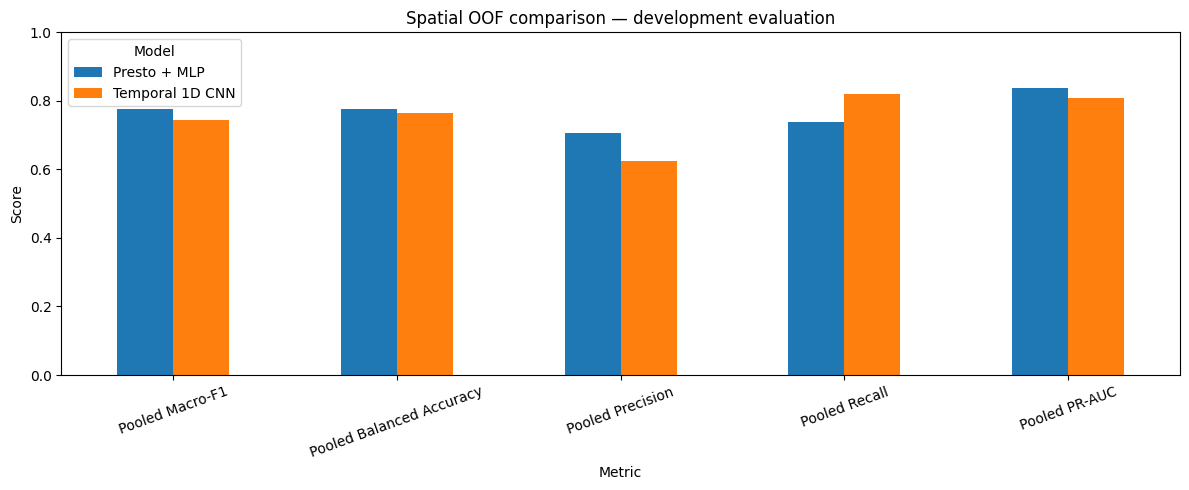

In [4]:
metrics_to_plot = ["Pooled Macro-F1", "Pooled Balanced Accuracy", "Pooled Precision", "Pooled Recall", "Pooled PR-AUC"]
ax = comparison.set_index("Model")[metrics_to_plot].T.plot(kind="bar", figsize=(12, 5))
ax.set_title("Spatial OOF comparison — development evaluation")
ax.set_ylabel("Score")
ax.set_xlabel("Metric")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


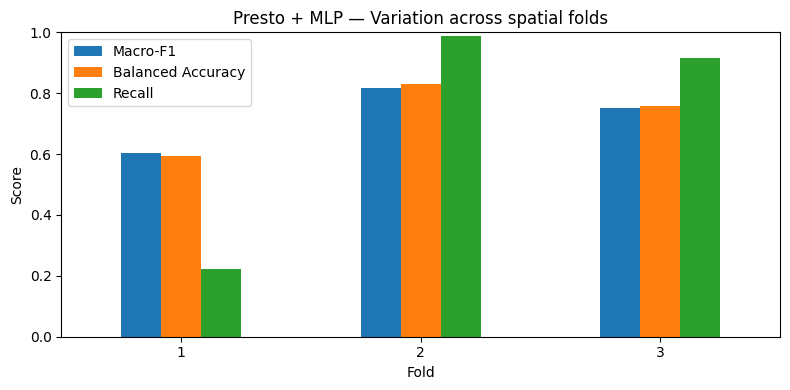

In [5]:
fold_results = pd.DataFrame({
    "Fold": [1, 2, 3],
    "Macro-F1": [0.603917, 0.817445, 0.750433],
    "Balanced Accuracy": [0.595069, 0.830722, 0.757185],
    "Recall": [0.221884, 0.987715, 0.915385],
})
ax = fold_results.set_index("Fold").plot(kind="bar", figsize=(8, 4))
ax.set_title("Presto + MLP — Variation across spatial folds")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


## 9. Confusion Matrix — محور 15%

الـConfusion Matrix المجمعة لتنبؤات Presto + MLP في EXP014-C2 كانت:

| الحقيقة \ التنبؤ | Predicted 0 | Predicted 1 |
|---|---:|---:|
| Actual 0 | TN = 1530 | FP = 344 |
| Actual 1 | FN = 294 | TP = 832 |

- **TN:** موقع من الفئة 0 وتنبأ به النموذج 0.
- **FP:** موقع من الفئة 0 لكن النموذج تنبأ به 1؛ إنذار إيجابي كاذب.
- **FN:** موقع من الفئة 1 لكن النموذج تنبأ به 0؛ حالة إيجابية فائتة.
- **TP:** موقع من الفئة 1 وتنبأ به النموذج 1.

من هذه القيم:

\[
Precision = \frac{TP}{TP+FP} = 0.7075
\]

\[
Recall = \frac{TP}{TP+FN} = 0.7389
\]

\[
Specificity = \frac{TN}{TN+FP} \approx 0.8164
\]

\[
BalancedAccuracy = \frac{Recall+Specificity}{2} = 0.7777
\]

**لماذا لا نكتفي بـAccuracy؟** لأن الفئات غير متوازنة بين الطيات، ولأن الخطأ في الفئة الإيجابية قد يكون أهم من الصحة الإجمالية. Macro-F1 يعطي وزنًا متساويًا لكل فئة، وBalanced Accuracy يوازن الحساسية والنوعية.

**تنبيه خاص:** هذه المصفوفة تخص C2 الذي استخدم `balanced` وThreshold 0.50. لا ننسبها إلى إعادة التدريب النهائي بـ`unweighted`؛ نتائج إعادة التدريب النهائية لا تُقاس على بيانات تدريبها.

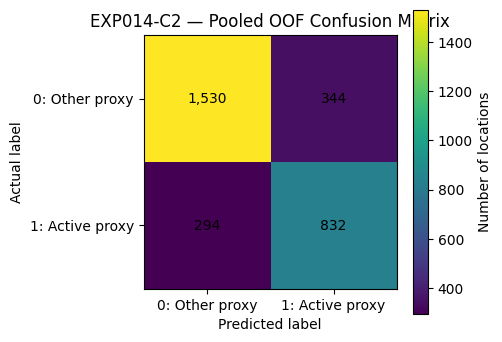

{'N': 3000, 'Precision': np.float64(0.707483), 'Recall': np.float64(0.738899), 'Specificity': np.float64(0.816435), 'Balanced Accuracy': np.float64(0.777667)}


In [6]:
# 9.1 رسم Confusion Matrix المقاسة في EXP014-C2
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

cm_c2 = np.array([[1530, 344], [294, 832]])
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm_c2)
ax.set_title("EXP014-C2 — Pooled OOF Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1], labels=["0: Other proxy", "1: Active proxy"])
ax.set_yticks([0, 1], labels=["0: Other proxy", "1: Active proxy"])
for (i, j), value in np.ndenumerate(cm_c2):
    ax.text(j, i, f"{value:,}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Number of locations")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_c2.ravel()
precision = tp / (tp + fp)
recall = tp / (tp + fn)
specificity = tn / (tn + fp)
balanced_accuracy = (recall + specificity) / 2
print({
    "N": int(cm_c2.sum()),
    "Precision": round(precision, 6),
    "Recall": round(recall, 6),
    "Specificity": round(specificity, 6),
    "Balanced Accuracy": round(balanced_accuracy, 6),
})
assert cm_c2.sum() == 3000


## 10. مقياس التعميم المناسب — محور 15%

### لماذا Spatial Validation؟

المواقع القريبة جغرافيًا قد تتشابه في التربة والغطاء الأرضي والظروف البيئية. Random split قد يضع نقاطًا متجاورة في Training وValidation فيرفع النتيجة بسبب التشابه المكاني بدل تعلّم نمط قابل للنقل. لذلك استخدم المشروع Outer spatial folds مع Buffer قدره 250 m وInner Leave-One-Block-Out لاختيار الإعدادات.

### المقياس الأساسي المقترح للمناقشة

**Equal-fold Macro-F1 = 0.723932 ± 0.109203** من EXP014-C2.

اخترناه ملخصًا أساسيًا لأن كل Fold يمثل وحدة جغرافية، ونريد ألا تهيمن الطية ذات العينات الأكثر على المتوسط. نعرض معه:

- Equal-fold Balanced Accuracy = `0.727659 ± 0.120569`.
- Pooled OOF Macro-F1 = `0.775162`، وهو متوسط موزون ضمنيًا بحجم كل طية.
- Pooled OOF Balanced Accuracy = `0.777667`.
- PR-AUC = `0.838809` وROC-AUC = `0.860548` كمقاييس فصل إضافية.
- Brier Score = `0.146522` وECE = `0.080991` لمعايرة الاحتمالات، مع الحذر من تغير التوزيع.

### لماذا نحتفظ بـEqual-fold وPooled معًا؟

Pooled OOF يجمع تنبؤات 3,000 نقطة فريدة، بينما Equal-fold يعطي كل منطقة/طية وزنًا متساويًا. اختلافهما ليس خطأ حسابيًا؛ بل يجيب كل واحد عن سؤال مختلف. لا يجوز تسمية أي منهما Independent External Test.

### أدلة على صعوبة التعميم

- Fold 1: Recall = `0.221884` فقط، مقارنةً بـ`0.987715` في Fold 2.
- تغير انتشار الفئة الإيجابية بين Train وValidation كان كبيرًا في الطيات الثلاث.
- تدقيق الأخطاء وجد أن Fold 2 وFold 3 أنتجا False Positives كثيرة لفئة `inactive_cropland`.
- بعض أنواع المحاصيل النشطة كانت صعبة في Fold 1، ومنها `mixed_or_other_crop` التي لم يكتشف منها النموذج أي حالة في عينة تلك الطية.

**الحكم:** لدينا Spatial Development Evaluation جيد التصميم، لكن ليس لدينا بعد اختبار خارجي مستقل ببيانات مرجعية مستقلة. لا تستخدم عبارة “النموذج يعمم على اليمن” في المناقشة.

## 11. الحفظ وقابلية التكرار — محور 10%

### معلومات المصدر المثبتة

| العنصر | القيمة |
|---|---|
| Presto repository | `NASA Harvest Presto` |
| Pinned commit | `11e207a668a34336ced1d8e492a1bd5849b96c4a` |
| Checkpoint | `default_model.pt` |
| Presto checkpoint SHA256 | `559c9d76f525bdf2dd3774da8b1e7f1510769b73baacac12e9e4d8d5c67fbe65` |
| Presto parameters | 822,682 — Frozen |
| MLP parameters | 8,386 — Trainable |
| C2 environment | Python 3.13.16, PyTorch 2.14.1+cu130, Tesla T4 |
| Fixed evaluation threshold | 0.50 |
| Spatial protocol | `buffer_250m_primary` |

### ما الذي يجب حفظه مع النموذج؟

1. `state_dict` الخاص بـMLP، لا النموذج كـPickle كامل.
2. `normalization.npz` الذي يحوي Mean وStd.
3. `final_model_config.json` ويشمل architecture وthreshold والـSeed ومصدر التسميات وإصدار Presto.
4. Presto checkpoint وملف تنفيذه الرسمي أو مرجع commit عند تشغيل مسار Raster-to-Embedding.
5. `model_card.md` يوضح الاستخدام والقيود والمقاييس التي تعود لتجربة C2.
6. SHA256 لكل ملف أساسي.

**مهم:** لا يمكن استنتاج أداء اختبار مستقل من نجاح حفظ Checkpoint. الحفظ يثبت إمكانية إعادة تحميل الـArtifact، لا جودة التعميم.

## 12. اتصال Google Drive وقراءة مسارات التجارب

هذه الخطوة تنفذ داخل **Google Colab**. عند تشغيل الخلية سيظهر طلب Google OAuth؛ وافق على ربط Drive بحسابك. لن نطلب منك كلمة مرور Google أو نسخ رموز OAuth إلى الدفتر.

سيتم الربط على المسار `/content/gdrive_recovery` للمحافظة على المسارات المستخدمة في تجارب Presto السابقة. بعد الربط، تتحقق الخلية من مجلدات المشروع والـEmbedding Cache وملفات الاختيار. لا يتم توليد بيانات بديلة أو Labels عند غياب الملفات.


In [7]:
from pathlib import Path
import os
import json
import hashlib
import numpy as np
import pandas as pd

# Google Drive OAuth: authorization happens in the user's Colab runtime.
try:
    from google.colab import drive
    drive.mount('/content/gdrive_recovery', force_remount=False)
except ModuleNotFoundError:
    print("هذه الجلسة ليست Google Colab. اربط Drive يدويًا أو عيّن DRIVE_ROOT إلى نسخة محلية موثوقة.")

DRIVE_ROOT_CANDIDATES = [
    Path('/content/gdrive_recovery/MyDrive'),
    Path('/content/drive/MyDrive'),
]
DRIVE_ROOT = next((p for p in DRIVE_ROOT_CANDIDATES if p.exists()), None)
if DRIVE_ROOT is None:
    raise RuntimeError(
        "Google Drive غير متصل. شغّل هذا الدفتر في Colab ووافق على OAuth، "
        "أو عيّن DRIVE_ROOT يدويًا إلى MyDrive الصحيح."
    )

print("Google Drive connected:", DRIVE_ROOT)
PROJECT_ROOT = DRIVE_ROOT / 'Yemen-CropWatch'
PILOT_ROOT = DRIVE_ROOT / 'Yemen-CropWatch-Sentinel2-Pilot'
REPORT_ROOT = PROJECT_ROOT / 'reports/model_training/dhamar_2024'

OUTER_SPLIT_ROOT = REPORT_ROOT / 'exp010d_final_spatial_protocols_v1/buffer_250m_primary'
A4_ROOT = REPORT_ROOT / 'exp011b_a4_all_outer_leave_one_block_v1'
C2_OUTPUT = REPORT_ROOT / 'exp014c_presto_outer_refit_v1'
C4A_OUTPUT = REPORT_ROOT / 'exp014c4a_inner_weight_threshold_selection_v1'
EMBEDDING_CACHE = C2_OUTPUT / 'embedding_cache/presto_outer_unique_embeddings_v1.npz'
FINAL_MODEL_DIR = REPORT_ROOT / 'final_model_v1'

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Pilot raster exists:", (PILOT_ROOT / 'dhamar_2024_annual_stack.tif').exists())
print("Embedding cache exists:", EMBEDDING_CACHE.exists())
print("C4A report exists:", (C4A_OUTPUT / 'exp014c4a_final_report.json').exists())


Google Colab Drive mount skipped: ModuleNotFoundError
Drive root not found. Set DRIVE_ROOT manually before data loading.
PROJECT_ROOT: /content/Yemen-CropWatch
Embedding cache exists: False
C4A report exists: False


## 13. فحص ملفات الـEmbeddings والـOuter Manifests

سيجمع هذا القسم ملفات `validation_samples.csv` للطيات الخارجية الثلاث بعد اكتمال اختيار الإعدادات، لأن اتحادها يمثل مجموعة المواقع ذات الإحداثيات الفريدة التي ظهرت مرة واحدة كـOuter Validation في البروتوكول المسجل. بعد إعادة التدريب النهائي، لن نستخدم هذه البيانات لإعلان نتيجة اختبار جديدة؛ ستصبح بيانات ملائمة لتدريب نموذج التسليم النهائي.

**قبل التنفيذ:** افحص أن أسماء أعمدة الإحداثيات `row` و`col` تطابق ملفاتك. إن كانت مختلفة، عدّل قائمة البدائل في الدالة أدناه بعد فحص الأعمدة، ولا تُحوّل إحداثيات جغرافية إلى Pixel coordinates دون استخدام Transform الصحيح.

In [8]:
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def find_row_col_columns(frame: pd.DataFrame):
    candidates = [("row", "col"), ("raster_row", "raster_col"), ("pixel_row", "pixel_col")]
    for row_name, col_name in candidates:
        if row_name in frame.columns and col_name in frame.columns:
            return row_name, col_name
    raise KeyError(
        "Could not find pixel row/column columns. Available columns: "
        + repr(frame.columns.tolist())
    )


def load_outer_validation_labels(outer_root: Path) -> pd.DataFrame:
    frames = []
    for fold in (1, 2, 3):
        path = outer_root / f"fold_{fold}" / "validation_samples.csv"
        if not path.exists():
            raise FileNotFoundError(f"Missing outer validation manifest: {path}")
        part = pd.read_csv(path)
        row_col = find_row_col_columns(part)
        part = part.copy()
        part["row"] = pd.to_numeric(part[row_col[0]], errors="raise").astype("int64")
        part["col"] = pd.to_numeric(part[row_col[1]], errors="raise").astype("int64")
        part["outer_fold"] = fold
        if "target_proxy" not in part.columns:
            raise KeyError(f"target_proxy missing in {path}")
        frames.append(part)
    labels = pd.concat(frames, ignore_index=True)
    labels["target_proxy"] = pd.to_numeric(labels["target_proxy"], errors="coerce")
    if labels["target_proxy"].isna().any():
        raise ValueError("Missing/non-numeric target_proxy found; do not infer missing labels.")
    labels["target_proxy"] = labels["target_proxy"].astype("int64")
    if not set(labels["target_proxy"].unique()).issubset({0, 1}):
        raise ValueError("target_proxy must contain only 0/1.")
    duplicates = labels.duplicated(["row", "col"]).sum()
    if duplicates:
        raise ValueError(f"Outer validation union contains {duplicates} duplicate row/col pairs.")
    return labels


# لا يتم تحميل البيانات إلا إذا كانت كل الملفات الأساسية موجودة.
DATA_FILES_READY = (
    EMBEDDING_CACHE.exists()
    and all((OUTER_SPLIT_ROOT / f"fold_{i}" / "validation_samples.csv").exists() for i in (1, 2, 3))
)

if DATA_FILES_READY:
    labels_df = load_outer_validation_labels(OUTER_SPLIT_ROOT)
    with np.load(EMBEDDING_CACHE, allow_pickle=False) as cache:
        print("Embedding cache keys:", cache.files)
        embeddings = np.asarray(cache["embeddings"], dtype=np.float32)
        coords = np.asarray(cache["coords"])
        complete_month_counts = np.asarray(cache["complete_month_counts"])
        metadata_raw = cache["metadata_json"].item() if "metadata_json" in cache.files else "{}"
    if coords.ndim != 2 or coords.shape[1] != 2:
        raise ValueError(f"Expected coords as (N,2) [row,col], got {coords.shape}.")
    coords = coords.astype("int64")
    if embeddings.shape != (len(coords), 128):
        raise ValueError(f"Expected embeddings shape (N,128), got {embeddings.shape}.")
    if len(np.unique(coords, axis=0)) != len(coords):
        raise ValueError("Embedding cache has duplicate coordinates.")
    if len(complete_month_counts) != len(coords) or not np.all(complete_month_counts == 12):
        raise ValueError("Incomplete or misaligned monthly sequences in embedding cache.")
    embedding_df = pd.DataFrame({"row": coords[:, 0], "col": coords[:, 1]})
    feature_columns = [f"embedding_{i:03d}" for i in range(128)]
    embedding_df[feature_columns] = embeddings
    final_df = labels_df.merge(embedding_df, on=["row", "col"], how="left", validate="one_to_one")
    if final_df[feature_columns].isna().any().any():
        missing_rows = int(final_df[feature_columns].isna().any(axis=1).sum())
        raise ValueError(f"{missing_rows} label rows do not have matching embeddings.")
    if len(final_df) != 3000:
        raise ValueError(f"Expected 3000 unique labelled coordinates from prior audit; found {len(final_df)}.")
    print("Labels:", len(labels_df), "Embeddings:", embeddings.shape, "Joined:", final_df.shape)
    print(final_df["target_proxy"].value_counts().sort_index())
else:
    labels_df = None
    final_df = None
    feature_columns = [f"embedding_{i:03d}" for i in range(128)]
    print("DATA FILES NOT READY — no dataset was fabricated and no labels were created.")


DATA FILES NOT READY — no dataset was fabricated and no labels were created.


## 14. تدقيق التسميات مقابل Source Class

التحقق التالي لا يغيّر `target_proxy`. هو يقارن فقط بين القاعدة المعلنة وقيمة `target_proxy` المسجلة. إذا كانت هناك فئة مصدرية غير معروفة أو اختلاف في Label، أوقف التنفيذ وافحص الـManifest الأصلي وسجل التدقيق.

In [9]:
if final_df is not None and "source_class" in final_df.columns:
    audit = final_df[["source_class", "target_proxy"]].copy()
    audit["derived_target"] = audit["source_class"].map(derive_proxy_label)
    unknown = audit["derived_target"].isna().sum()
    mismatch = (audit["derived_target"].notna() & (audit["derived_target"] != audit["target_proxy"])).sum()
    print("Unknown source classes:", int(unknown))
    print("Derived-vs-recorded target mismatches:", int(mismatch))
    if unknown or mismatch:
        raise ValueError("Label audit failed. Stop before final training; do not auto-correct labels.")
    print("Label mapping audit: PASS")
else:
    print("Label audit deferred: dataset is not loaded or source_class column is absent.")


Label audit deferred: dataset is not loaded or source_class column is absent.


## 15. إعادة تدريب رأس التصنيف النهائي وحفظه

### لماذا نعيد التدريب؟

EXP014-C2 درّب رؤوسًا مستقلة داخل Outer folds باستخدام `balanced`. أما C4A فقد اختار `unweighted` وThreshold `0.50` من Inner Spatial Validation. لذلك لا ننسب نتائج C2 إلى الإعدادات الجديدة. في هذه الخطوة نثبت الإعدادات المختارة، ثم نعيد ملاءمة MLP على جميع المواقع المتاحة بعد اكتمال Model Selection.

### قيد التقييم

بما أن اتحاد الـOuter Validation سبق استخدامه في التطوير، فهو يُستخدم الآن لتدريب Artifact التسليم، وليس لقياس أداء مستقل. لا تحسب Macro-F1 على بيانات التدريب لتسميته تعميمًا. لا تستخدم Previous Test.

### الإعدادات النهائية

`unweighted`, `threshold=0.50`, `epochs=1`, `batch_size=64`, `AdamW(lr=0.001, weight_decay=0.0001)`, `dropout=0.30`, `seed=14017`.

**تفعيل التدريب:** غيّر `EXECUTE_FINAL_FIT` إلى `True` بعد نجاح كل الفحوص السابقة.

In [10]:
# 15.1 Final refit — لا يبدأ قبل توفر البيانات وتجاوز التدقيق
EXECUTE_FINAL_FIT = False  # غيّرها إلى True في Colab بعد فحص ملفات Drive
FINAL_SEED = 14017
FINAL_EPOCHS = 1
FINAL_BATCH_SIZE = 64
FINAL_THRESHOLD = 0.50
FINAL_LEARNING_RATE = 1e-3
FINAL_WEIGHT_DECAY = 1e-4

final_artifact_status = "NOT_RUN"
final_model = None

if EXECUTE_FINAL_FIT:
    if final_df is None:
        raise RuntimeError("Cannot train: embedding cache/manifests were not loaded.")
    if "source_class" in final_df.columns:
        # لا تبدأ إذا لم ينجح تدقيق التسميات أعلاه.
        assert final_df["source_class"].map(derive_proxy_label).notna().all()
    
    import random
    from torch.utils.data import TensorDataset, DataLoader

    random.seed(FINAL_SEED)
    np.random.seed(FINAL_SEED)
    torch.manual_seed(FINAL_SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(FINAL_SEED)
    torch.use_deterministic_algorithms(False)

    X = final_df[feature_columns].to_numpy(dtype=np.float32)
    y = final_df["target_proxy"].to_numpy(dtype=np.int64)
    if X.shape != (3000, 128) or not np.isfinite(X).all():
        raise ValueError("Embedding array shape/finiteness check failed.")
    if not set(np.unique(y)).issubset({0, 1}) or len(np.unique(y)) != 2:
        raise ValueError("Both binary classes must exist; no automatic relabeling is allowed.")

    # Final scaler is fitted on the full training dataset only, after model selection.
    x_mean = X.mean(axis=0).astype(np.float32)
    x_std = X.std(axis=0).astype(np.float32)
    x_std[x_std < 1e-6] = 1.0
    X_scaled = (X - x_mean) / x_std

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    final_model = MLPHead().to(device)
    optimizer = torch.optim.AdamW(
        final_model.parameters(), lr=FINAL_LEARNING_RATE,
        weight_decay=FINAL_WEIGHT_DECAY
    )
    loss_fn = nn.CrossEntropyLoss()  # unweighted
    dataset = TensorDataset(
        torch.tensor(X_scaled, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long),
    )
    generator = torch.Generator().manual_seed(FINAL_SEED)
    loader = DataLoader(
        dataset, batch_size=FINAL_BATCH_SIZE, shuffle=True,
        generator=generator, drop_last=False
    )

    final_model.train()
    epoch_losses = []
    for epoch in range(FINAL_EPOCHS):
        batch_losses = []
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = final_model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(final_model.parameters(), max_norm=1.0)
            optimizer.step()
            batch_losses.append(float(loss.detach().cpu()))
        epoch_loss = float(np.mean(batch_losses))
        epoch_losses.append(epoch_loss)
        print(f"Epoch {epoch + 1}/{FINAL_EPOCHS} — mean batch loss: {epoch_loss:.6f}")

    FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)
    state_path = FINAL_MODEL_DIR / "final_mlp_state_dict.pt"
    norm_path = FINAL_MODEL_DIR / "normalization.npz"
    config_path = FINAL_MODEL_DIR / "final_model_config.json"

    # Save state_dict only; loading uses weights_only=True in the API.
    torch.save({k: v.detach().cpu() for k, v in final_model.state_dict().items()}, state_path)
    np.savez_compressed(norm_path, mean=x_mean, std=x_std)

    config = {
        "project": "Yemen-CropWatch",
        "model_version": "final_candidate_v1",
        "encoder": "NASA Harvest Presto",
        "encoder_commit": "11e207a668a34336ced1d8e492a1bd5849b96c4a",
        "encoder_checkpoint_sha256_expected": "559c9d76f525bdf2dd3774da8b1e7f1510769b73baacac12e9e4d8d5c67fbe65",
        "encoder_trainable": False,
        "head_architecture": "Linear(128,64)-GELU-Dropout(0.30)-Linear(64,2)",
        "head_trainable_parameters": 8386,
        "training_data": "union_of_three_outer_validation_manifests_after_model_selection",
        "n_training_samples": int(len(y)),
        "class_counts": {str(k): int(v) for k, v in pd.Series(y).value_counts().sort_index().items()},
        "label_definition": "target_proxy; 1=active crop-related source classes, 0=other mapped source classes",
        "labels_are_provisional_proxy_labels": True,
        "class_weighting": "unweighted",
        "threshold": FINAL_THRESHOLD,
        "epochs": FINAL_EPOCHS,
        "batch_size": FINAL_BATCH_SIZE,
        "optimizer": "AdamW",
        "learning_rate": FINAL_LEARNING_RATE,
        "weight_decay": FINAL_WEIGHT_DECAY,
        "gradient_clip_norm": 1.0,
        "normalization": "z_score_fitted_on_full_final_training_set",
        "seed": FINAL_SEED,
        "device_used": str(device),
        "training_loss_by_epoch": epoch_losses,
        "independent_external_test_available": False,
        "outer_validation_reused_for_final_fit_after_model_selection": True,
        "previous_test_accessed": False,
        "performance_claim": "Do not assign EXP014-C2 metrics to this unweighted final refit; no independent test score was measured.",
    }
    config_path.write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
    
    final_artifact_status = "SAVED"
    print("Saved:", state_path)
    print("Saved:", norm_path)
    print("Saved:", config_path)
else:
    print("Final refit is disabled. Set EXECUTE_FINAL_FIT=True after all data/label checks pass.")


Final refit is disabled. Set EXECUTE_FINAL_FIT=True after all data/label checks pass.


## 16. Model Card — وثيقة تعريف النموذج

تُنشأ وثيقة Model Card بعد التدريب. يجب أن تتضمن:

- الاستخدام المقصود: تصنيف Proxy لتمثيل موقع زمني في Dhamar pilot.
- المستخدمون: فريق البحث/المطورون، وليس اعتمادًا زراعيًا ميدانيًا آليًا.
- مصدر البيانات والفترة والموقع.
- تعريف التسميات وحدودها.
- معمارية Encoder + Head وأبعاد الـTensor.
- طريقة التقسيم والتقييم المكاني.
- النتائج المقاسة من C2 مع تسمية واضحة أنها تعود لإعداد `balanced`.
- إعداد C4A المعتمد للتدريب النهائي (`unweighted`, `0.50`).
- القيود، والانحيازات، والحاجة إلى بيانات مستقلة وGround Truth ميدانية.

In [11]:
if final_artifact_status == "SAVED":
    config = json.loads((FINAL_MODEL_DIR / "final_model_config.json").read_text(encoding="utf-8"))
    model_card = f"""# Yemen-CropWatch — Model Card

## Model identity
- Version: {config['model_version']}
- Encoder: {config['encoder']} (frozen)
- Head: {config['head_architecture']}
- Trainable head parameters: {config['head_trainable_parameters']:,}

## Intended use
Research prototype for a binary crop-related vegetation proxy classification task in the Dhamar 2024 pilot.

## Labels
- 1: active crop-related proxy classes
- 0: mapped other land-cover proxy classes
- Labels are provisional proxy labels, not independently field-verified ground truth.

## Final fitting
- Samples: {config['n_training_samples']}
- Class weighting: {config['class_weighting']}
- Threshold: {config['threshold']}
- Epochs: {config['epochs']}
- Seed: {config['seed']}

## Evaluation caveat
EXP014-C2 outer-fold metrics were obtained with balanced class weighting. They are historical development metrics and must not be reported as measured performance of this unweighted final refit. The outer validation data were reused for final fitting after model selection; no independent external test score is available.

## Known limitations
- Proxy labels; no independent field verification.
- Dhamar pilot and 2024 imagery only.
- This classifier expects a 128-dimensional Presto embedding; the raw-raster-to-embedding service must be integrated before arbitrary new locations can be scored through the website.
"""
    (FINAL_MODEL_DIR / "model_card.md").write_text(model_card, encoding="utf-8")
    print(model_card)
else:
    print("Model Card generation waits until final artifact is saved.")


Model Card generation waits until final artifact is saved.


## 17. فحص قابلية إعادة التحميل وSHA256

نجاح هذا الفحص يثبت أن الأوزان محفوظة ويمكن تحميلها ببنية MLP نفسها، وأن ملف Normalization موجود. لا يُعد هذا اختبارًا لجودة التعميم.

In [12]:
if final_artifact_status == "SAVED":
    state_path = FINAL_MODEL_DIR / "final_mlp_state_dict.pt"
    norm_path = FINAL_MODEL_DIR / "normalization.npz"
    config_path = FINAL_MODEL_DIR / "final_model_config.json"

    safe_state = torch.load(state_path, map_location="cpu", weights_only=True)
    reloaded = MLPHead()
    reloaded.load_state_dict(safe_state, strict=True)
    reloaded.eval()
    with np.load(norm_path, allow_pickle=False) as norm:
        assert norm["mean"].shape == (128,)
        assert norm["std"].shape == (128,)
        assert np.all(norm["std"] > 0)
    smoke_logits = reloaded(torch.zeros(2, 128))
    assert smoke_logits.shape == (2, 2)

    for artifact in [state_path, norm_path, config_path, FINAL_MODEL_DIR / "model_card.md"]:
        print(artifact.name, "SHA256=", sha256_file(artifact))
    print("Model reload smoke test: PASS")
else:
    print("Reload verification skipped: final model not saved yet.")


Reload verification skipped: final model not saved yet.


## 18. ربط النموذج بالموقع — حدود التكامل

### واجهة الاستدلال التي نجهزها

نقطة API تستقبل Presto embedding بطول 128 وتعيد:

- `predicted_label`.
- `probability_0` و`probability_1`.
- `threshold` المستخدم.
- تحذير بأن النتيجة مبنية على Proxy Labels وليست إثباتًا حقليًا.

### ما الذي لم يُنجز بعد؟

التجارب الحالية جهزت Embedding Cache للعينات المعروفة، لكنها لا تقدم حتى الآن خدمة إنتاجية تحول أي إحداثية جديدة إلى Sentinel‑2 time series ثم إلى Presto embedding. لذلك API في هذه الحزمة **لا تستقبل GeoTIFF ولا إحداثيات خام**؛ تستقبل فقط embedding جاهزًا من 128 قيمة.

لتحويل الموقع إلى منتج تشغيل كامل، يجب إضافة خدمة مستقلة:

`Coordinate/Area → imagery acquisition → cloud masking & compositing → 17-channel Presto tensor → Presto embedding → MLP API`.

لا يجوز إظهار تنبؤ لأي مكان جديد قبل اكتمال هذه السلسلة والتحقق من جودة صور الإدخال.

## 19. معايير الجودة والأمن وتجربة المستخدم

المعايير التالية تُستخدم كـ**أطر تصميم واختبار**. إدراجها في المشروع لا يعني الحصول على شهادة امتثال.

| المجال | المرجع المقترح | كيف نطبقه في Yemen-CropWatch |
|---|---|---|
| جودة المنتج | ISO/IEC 25010:2023 | متطلبات واختبارات للوظائف، الأداء، التوافق، الاعتمادية، الأمن، الصيانة والمرونة |
| UX/HCD | ISO 9241-210:2019 | مقابلات مستخدمين، مهام قابلة للقياس، اختبار قابلية الاستخدام، تكرار التصميم |
| Accessibility | WCAG 2.2 AA | لوحة مفاتيح، Focus ظاهر، تباين، Labels، تكبير، أحجام أهداف لمس مناسبة |
| الأمن السيبراني | ISO/IEC 27001:2022 | سجل أصول ومخاطر، صلاحيات، نسخ احتياطي، إدارة الحوادث، مراجعات أمنية |
| أمن التطبيق | OWASP ASVS 5.0.0 | قائمة تحقق للتحقق من المصادقة، التفويض، التحقق من المدخلات، الجلسات، التهيئة الآمنة |
| الخصوصية | ISO/IEC 27701:2025 | تقليل بيانات PII، تحديد الغرض والاحتفاظ، ضوابط الوصول وحقوق أصحاب البيانات عند انطباقها |
| التطوير الآمن | NIST SP 800-218 SSDF 1.1 | مراجعة الكود، إدارة الاعتماديات، بناء موثوق، تتبع الثغرات وإصدارات النشر |

### مصادر رسمية للتحقق من الإصدارات

- ISO/IEC 25010:2023 — https://www.iso.org/standard/78176.html
- ISO 9241-210:2019 — https://www.iso.org/standard/77520.html
- WCAG 2.2 — https://www.w3.org/TR/WCAG22/
- ISO/IEC 27001:2022 — https://www.iso.org/standard/27001
- OWASP ASVS 5.0.0 — https://asvs.owasp.org/
- ISO/IEC 27701:2025 — https://committee.iso.org/standard/27701
- NIST SP 800-218 SSDF 1.1 — https://csrc.nist.gov/pubs/sp/800/218/final

**قيد قانوني:** مراجعة المتطلبات القانونية الخاصة باليمن وأي دولة يستضاف فيها الموقع تحتاج مراجعة قانونية مختصة. لا يستنتج الامتثال القانوني من استخدام هذه المعايير وحده.

## 20. خطة الموقع من البداية إلى التشغيل

كل مرحلة لها مدخلات وأنشطة ومخرجات ومسؤول اعتماد ومعيار قبول.

| المرحلة | المدخلات | الأنشطة | المخرجات | مسؤول الاعتماد | معيار القبول |
|---|---|---|---|---|---|
| 1. Project Initiation | مشكلة المشروع ونتائج pilot | تحديد الرؤية والنطاق والمخاطر | Project Charter | مشرف المشروع | أهداف ونطاق وحدود معتمدة |
| 2. Research & Analysis | احتياجات المستخدمين والسياق | مقابلات وتحليل الاستخدام والمنافسين | Research Report | قائد التحليل | احتياجات موثقة مع أدلة |
| 3. Requirements Engineering | Research Report | Functional/NFRs، Use Cases، Acceptance Criteria | SRS + Traceability Matrix | محلل النظم | كل متطلب له اختبار قبول |
| 4. Content & Localization | SRS | هيكل الصفحات، العربية RTL، المصطلحات | Sitemap + Content Model | مسؤول المحتوى | تغطية المحتوى واللغة |
| 5. Brand Identity | الجمهور والسياق | شعار وألوان وخطوط ونظام بصري | Brand Guide | مالك المنتج | اتساق بصري وتباين مناسب |
| 6. UX/UI | Sitemap والمتطلبات | Wireframes، Prototype، User Testing | UI Kit + Prototype | UX Lead | نجاح المهام الأساسية في اختبار الاستخدام |
| 7. Software Architecture | NFRs وPrototype | API، Database، Deployment، Threat Model | Architecture Decision Records | مهندس النظام | مراجعة الأمن والأداء والتوسع |
| 8. Development | التصميم والمعمارية | Frontend، Backend، Model API، Tests | Source Code + CI | قائد التطوير | Build ناجح وCode Review |
| 9. Quality Assurance | Build والمتطلبات | Functional، API، Security، Accessibility tests | QA Report | مسؤول QA | لا توجد عيوب حرجة مفتوحة |
| 10. Deployment | QA approval | Staging، secrets، HTTPS، monitoring | Release + Rollback plan | DevOps/مالك الخدمة | Health checks، TLS، rollback مجرّب |
| 11. Operations | Release ومؤشرات | Monitoring، Backup، Incident response، تحسين | Operations Log + Releases | مسؤول التشغيل | استقرار ومراجعة دورية |

### سياسة النشر المرحلي

1. Local development.
2. Staging مع بيانات غير حساسة.
3. Security + accessibility + functional QA.
4. Production بعد موافقة المالك ومسؤول الأمن.
5. مراقبة الأداء والأخطاء ونسخ احتياطي وخطة Rollback.

**لا يتم نشر النموذج كخدمة زراعية تشغيلية قبل استكمال Raw Raster → Presto pipeline والتحقق الخارجي المستقل.**

## 21. واجهة API للاختبار المحلي فقط (FastAPI + HTML)

هذا القسم يحتفظ بنموذج API كـ**مرجع تكامل واختبار محلي** بعد توفر أوزان النموذج. لا يتم نشر هذه الخدمة على منصة أخرى، ولا يتم تشغيلها على GitHub Pages.

- صفحة تعريف عربية RTL متاحة من الجذر `/` عند تشغيل FastAPI محليًا.
- `/health` لفحص الخدمة محليًا.
- `/model-info` لعرض وصف النموذج وحدوده.
- `/predict` لاستقبال Presto embedding بطول 128.
- تحميل `state_dict` باستخدام `weights_only=True`.
- لا يدعم حاليًا Raw Raster أو الإحداثيات؛ استكمال Raster → Presto pipeline شرط قبل أي خدمة تنبؤ.

**النشر الوحيد في هذا الدفتر:** موقع Static عبر GitHub Pages. تشغيل FastAPI في القسم 21.2 هو معاينة محلية داخل Colab فقط، وليس رابطًا دائمًا عامًا.


In [13]:
# 21.1 توليد ملفات مشروع الويب بعد حفظ النموذج النهائي
CREATE_WEB_PACKAGE = False  # اجعلها True بعد final_artifact_status == "SAVED"
WEB_ROOT = PROJECT_ROOT / "deployment" / "web_api"

APP_PY = r'''from pathlib import Path
import json
import os
import secrets
from typing import List

import numpy as np
import torch
from torch import nn
from fastapi import FastAPI, Header, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from fastapi.responses import FileResponse
from fastapi.staticfiles import StaticFiles
from pydantic import BaseModel, Field

BASE_DIR = Path(__file__).resolve().parent
ARTIFACTS = BASE_DIR / "model_artifacts"
STATE_PATH = ARTIFACTS / "final_mlp_state_dict.pt"
NORM_PATH = ARTIFACTS / "normalization.npz"
CONFIG_PATH = ARTIFACTS / "final_model_config.json"

class MLPHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(128, 64), nn.GELU(), nn.Dropout(0.30), nn.Linear(64, 2)
        )
    def forward(self, x):
        return self.network(x)

app = FastAPI(title="Yemen-CropWatch Model API", version="1.0.0")
allowed_origins = [x.strip() for x in os.getenv("ALLOWED_ORIGINS", "http://localhost:8000").split(",") if x.strip()]
app.add_middleware(
    CORSMiddleware,
    allow_origins=allowed_origins,
    allow_credentials=False,
    allow_methods=["GET", "POST"],
    allow_headers=["Content-Type", "X-API-Key"],
)

model = None
x_mean = None
x_std = None
model_config = None
load_error = None

try:
    if not (STATE_PATH.exists() and NORM_PATH.exists() and CONFIG_PATH.exists()):
        raise FileNotFoundError("Model artifacts are missing from model_artifacts/.")
    model_config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
    with np.load(NORM_PATH, allow_pickle=False) as norm:
        x_mean = norm["mean"].astype(np.float32)
        x_std = norm["std"].astype(np.float32)
    if x_mean.shape != (128,) or x_std.shape != (128,) or np.any(x_std <= 0):
        raise ValueError("Invalid normalization vectors.")
    # Only load a weights-only state_dict; never unpickle arbitrary user files.
    state = torch.load(STATE_PATH, map_location="cpu", weights_only=True)
    model = MLPHead()
    model.load_state_dict(state, strict=True)
    model.eval()
except Exception as exc:
    load_error = f"{type(exc).__name__}: {exc}"

class PredictRequest(BaseModel):
    embedding: List[float] = Field(min_length=128, max_length=128)

class PredictResponse(BaseModel):
    predicted_label: int
    label_name: str
    probability_0: float
    probability_1: float
    threshold: float
    warning: str

API_KEY = os.getenv("MODEL_API_KEY", "")

def check_api_key(x_api_key: str | None):
    if API_KEY and not (x_api_key and secrets.compare_digest(x_api_key, API_KEY)):
        raise HTTPException(status_code=401, detail="Unauthorized")

@app.get("/health")
def health():
    return {"status": "ok" if model is not None else "model_unavailable", "model_loaded": model is not None}

@app.get("/model-info")
def model_info():
    if model_config is None:
        raise HTTPException(status_code=503, detail=load_error or "Model unavailable")
    return {
        "project": "Yemen-CropWatch",
        "model_version": model_config.get("model_version"),
        "encoder": "Frozen Presto",
        "head": model_config.get("head_architecture"),
        "embedding_dimension": 128,
        "threshold": model_config.get("threshold", 0.5),
        "labels_are_provisional_proxy_labels": True,
        "independent_external_test_available": False,
        "raw_raster_inference_available": False,
    }

@app.post("/predict", response_model=PredictResponse)
def predict(request: PredictRequest, x_api_key: str | None = Header(default=None)):
    check_api_key(x_api_key)
    if model is None:
        raise HTTPException(status_code=503, detail=load_error or "Model unavailable")
    vector = np.asarray(request.embedding, dtype=np.float32)
    if vector.shape != (128,) or not np.isfinite(vector).all():
        raise HTTPException(status_code=422, detail="Embedding must contain 128 finite values.")
    normalized = (vector - x_mean) / x_std
    with torch.inference_mode():
        logits = model(torch.from_numpy(normalized).unsqueeze(0))
        probabilities = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
    threshold = float(model_config.get("threshold", 0.5))
    predicted = int(probabilities[1] >= threshold)
    return PredictResponse(
        predicted_label=predicted,
        label_name="active_crop_proxy" if predicted == 1 else "other_landcover_proxy",
        probability_0=float(probabilities[0]),
        probability_1=float(probabilities[1]),
        threshold=threshold,
        warning="Proxy-label research output; not field-verified. Input must be generated by the approved Presto preprocessing pipeline.",
    )

@app.get("/")
def home():
    return FileResponse(BASE_DIR / "index.html")
'''

INDEX_HTML = r'''<!doctype html>
<html lang="ar" dir="rtl">
<head>
  <meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
  <meta name="description" content="Yemen-CropWatch research prototype for Sentinel-2 time-series analysis.">
  <title>Yemen-CropWatch</title>
  <style>
    :root { font-family: system-ui, sans-serif; color: #182230; background: #f5f7fa; }
    body { margin: 0; line-height: 1.7; }
    main { max-width: 920px; margin: 40px auto; padding: 24px; }
    .card { background: white; border: 1px solid #d8dee8; border-radius: 16px; padding: 24px; margin: 16px 0; }
    h1, h2 { line-height: 1.3; }
    .status { display: inline-block; padding: 4px 12px; border-radius: 20px; background: #eef2f7; }
    code { direction: ltr; unicode-bidi: embed; }
    a { color: #1356a2; }
    :focus-visible { outline: 3px solid #1356a2; outline-offset: 3px; }
  </style>
</head>
<body>
<main>
  <header class="card">
    <p class="status">نموذج بحثي تجريبي</p>
    <h1>Yemen-CropWatch</h1>
    <p>تحليل سلاسل Sentinel-2 الزمنية باستخدام Frozen Presto Encoder ورأس تصنيف MLP.</p>
  </header>
  <section class="card" aria-labelledby="scope-title">
    <h2 id="scope-title">نطاق النسخة الحالية</h2>
    <p>منطقة الدراسة: Dhamar pilot — بيانات Sentinel-2 لعام 2024.</p>
    <p>المخرج تصنيف Proxy ثنائي، وليس إثباتًا حقليًا لوجود محصول أو توصية زراعية.</p>
  </section>
  <section class="card" aria-labelledby="status-title">
    <h2 id="status-title">حالة خدمة النموذج</h2>
    <p id="health" role="status" aria-live="polite">جارٍ فحص الخدمة…</p>
    <p>تستقبل واجهة النموذج Presto embedding بطول 128 فقط. لا تدعم هذه النسخة رفع GeoTIFF أو التنبؤ من إحداثيات خام.</p>
  </section>
  <section class="card">
    <h2>المنهجية والقيود</h2>
    <ul>
      <li>Presto Encoder مجمّد، وMLP رأس تصنيف صغير.</li>
      <li>التسميات الحالية Proxy Labels وليست Ground Truth ميدانية مستقلة.</li>
      <li>لا تتوفر نتيجة اختبار خارجي مستقل في النسخة الحالية.</li>
      <li>يجب استكمال خط تجهيز صور الأقمار الصناعية قبل إتاحة تنبؤات لمواقع جديدة.</li>
    </ul>
  </section>
</main>
<script>
fetch('/health').then(r => r.json()).then(d => {
  document.getElementById('health').textContent = d.model_loaded ? 'النموذج محمّل وجاهز لاستقبال embeddings.' : 'الخدمة تعمل لكن النموذج غير محمّل؛ راجع ملفات النشر.';
}).catch(() => {
  document.getElementById('health').textContent = 'تعذر الاتصال بخدمة النموذج.';
});
</script>
</body></html>
'''

REQUIREMENTS_TXT = """fastapi>=0.115,<1
uvicorn[standard]>=0.30,<1
pydantic>=2.7,<3
numpy>=1.26,<3
torch>=2.2,<3
"""

if CREATE_WEB_PACKAGE:
    if final_artifact_status != "SAVED":
        raise RuntimeError("Save the final model before creating the website package.")
    artifact_dir = WEB_ROOT / "model_artifacts"
    artifact_dir.mkdir(parents=True, exist_ok=True)
    for name in ["final_mlp_state_dict.pt", "normalization.npz", "final_model_config.json", "model_card.md"]:
        source = FINAL_MODEL_DIR / name
        if not source.exists():
            raise FileNotFoundError(source)
        (artifact_dir / name).write_bytes(source.read_bytes())
    (WEB_ROOT / "app.py").write_text(APP_PY, encoding="utf-8")
    (WEB_ROOT / "index.html").write_text(INDEX_HTML, encoding="utf-8")
    (WEB_ROOT / "requirements.txt").write_text(REQUIREMENTS_TXT, encoding="utf-8")
    print("Local FastAPI preview sources generated at:", WEB_ROOT)
    print("These files are not included in GitHub Pages and are not deployed as a public API.")
else:
    print("Web package generation disabled. Enable after final model save.")


Web package generation disabled. Enable after final model save.


## 21.2 تشغيل الموقع وفتحه تلقائيًا

بعد حفظ النموذج النهائي ووجود ملفات `final_model_v1`، شغّل هذه الخلية. ستقوم تلقائيًا بإنشاء حزمة الموقع إن لم تكن موجودة، وتشغيل FastAPI، والتحقق من `/health`، ثم عرض الموقع داخل الدفتر وفتح رابط في المتصفح عندما تسمح بيئة التشغيل.

**مهم:** هذا تشغيل محلي/داخل جلسة Colab، وليس نشرًا عامًا على الإنترنت. يتوقف الرابط عند إيقاف جلسة Colab أو الخادم. لا تبدأ الخلية التدريب تلقائيًا، ولا تنشئ نموذجًا أو تسميات بديلة عند غياب الملفات.


In [ ]:
# 21.2 Auto-build (when saved artifacts exist), start the web app, and open it.
from pathlib import Path
import importlib.util
import json
import os
import socket
import subprocess
import sys
import time
import urllib.request
import urllib.error
import webbrowser

from IPython.display import HTML, IFrame, Javascript, display

# 1) Check the actual saved model artifacts. Do not fabricate or auto-train.
required_model_files = [
    "final_mlp_state_dict.pt",
    "normalization.npz",
    "final_model_config.json",
]
missing_model_files = [
    name for name in required_model_files
    if not (FINAL_MODEL_DIR / name).is_file()
]

if missing_model_files:
    print("لم يتم تشغيل الموقع؛ ملفات النموذج النهائي غير مكتملة:")
    for name in missing_model_files:
        print(" -", FINAL_MODEL_DIR / name)
    print("نفّذ فحص البيانات والتسميات، ثم فعّل EXECUTE_FINAL_FIT=True في خلية Final Refit.")
    print("بعد نجاح الحفظ، أعد تشغيل خلية 21.2 هذه فقط.")
else:
    # 2) The previous cell defines these website source files.
    required_web_sources = ["APP_PY", "INDEX_HTML", "REQUIREMENTS_TXT"]
    missing_web_sources = [name for name in required_web_sources if name not in globals()]
    if missing_web_sources:
        raise RuntimeError(
            "شغّل خلية 21.1 الخاصة بتجهيز حزمة الموقع أولًا. المتغيرات المفقودة: "
            + ", ".join(missing_web_sources)
        )

    WEB_ROOT = Path(WEB_ROOT)
    ARTIFACT_DIR = WEB_ROOT / "model_artifacts"
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    WEB_ROOT.mkdir(parents=True, exist_ok=True)

    # Copy only verified artifacts from final_model_v1.
    for name in required_model_files:
        source = FINAL_MODEL_DIR / name
        destination = ARTIFACT_DIR / name
        destination.write_bytes(source.read_bytes())
    optional_model_card = FINAL_MODEL_DIR / "model_card.md"
    if optional_model_card.is_file():
        (ARTIFACT_DIR / "model_card.md").write_bytes(optional_model_card.read_bytes())

    (WEB_ROOT / "app.py").write_text(APP_PY, encoding="utf-8")
    (WEB_ROOT / "index.html").write_text(INDEX_HTML, encoding="utf-8")
    (WEB_ROOT / "requirements.txt").write_text(REQUIREMENTS_TXT, encoding="utf-8")
    print("Web app package ready:", WEB_ROOT)

    # 3) Check/install only the web-server packages. Do not reinstall torch/numpy.
    missing_packages = [
        package for module, package in (("fastapi", "fastapi>=0.115,<1"), ("uvicorn", "uvicorn[standard]>=0.30,<1"))
        if importlib.util.find_spec(module) is None
    ]
    if missing_packages:
        print("Installing missing web dependencies:", missing_packages)
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])
        except subprocess.CalledProcessError as exc:
            raise RuntimeError(
                "تعذر تثبيت متطلبات تشغيل الموقع. نفّذ يدويًا: "
                "pip install 'fastapi>=0.115,<1' 'uvicorn[standard]>=0.30,<1'"
            ) from exc

    # 4) Reuse a live Yemen-CropWatch server if this cell was run previously.
    def _health_at(candidate_port):
        try:
            with urllib.request.urlopen(f"http://127.0.0.1:{candidate_port}/health", timeout=1.5) as response:
                health_payload = json.loads(response.read().decode("utf-8"))
            with urllib.request.urlopen(f"http://127.0.0.1:{candidate_port}/model-info", timeout=1.5) as response:
                info_payload = json.loads(response.read().decode("utf-8"))
            return (
                isinstance(health_payload, dict)
                and "model_loaded" in health_payload
                and isinstance(info_payload, dict)
                and info_payload.get("project") == "Yemen-CropWatch"
            )
        except Exception:
            return False

    server_port = None
    for candidate in range(8000, 8020):
        if _health_at(candidate):
            server_port = candidate
            print("Reusing existing Yemen-CropWatch server on port", server_port)
            break

    server_process = None
    if server_port is None:
        for candidate in range(8000, 8020):
            with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as sock:
                try:
                    sock.bind(("127.0.0.1", candidate))
                    server_port = candidate
                    break
                except OSError:
                    continue
        if server_port is None:
            raise RuntimeError("لم أجد منفذًا متاحًا بين 8000 و8019.")

        is_colab = "google.colab" in sys.modules or importlib.util.find_spec("google.colab") is not None
        bind_host = "0.0.0.0" if is_colab else "127.0.0.1"
        log_path = WEB_ROOT / "server.log"
        log_handle = open(log_path, "a", encoding="utf-8")
        server_process = subprocess.Popen(
            [sys.executable, "-m", "uvicorn", "app:app", "--host", bind_host, "--port", str(server_port)],
            cwd=str(WEB_ROOT),
            stdout=log_handle,
            stderr=subprocess.STDOUT,
            start_new_session=True,
        )
        # Keep handles alive in the notebook kernel while the server runs.
        globals()["_YEMEN_CW_SERVER_PROCESS"] = server_process
        globals()["_YEMEN_CW_SERVER_LOG_HANDLE"] = log_handle

        ready = False
        for _ in range(40):
            if server_process.poll() is not None:
                break
            if _health_at(server_port):
                ready = True
                break
            time.sleep(0.5)
        if not ready:
            try:
                log_handle.flush()
                log_text = log_path.read_text(encoding="utf-8", errors="replace")[-4000:]
            except Exception:
                log_text = "تعذر قراءة سجل الخادم."
            raise RuntimeError(
                f"لم تصبح الخدمة جاهزة على المنفذ {server_port}. سجل الخادم:\n{log_text}"
            )

    local_url = f"http://127.0.0.1:{server_port}/"
    print("Website health:", json.dumps(json.loads(urllib.request.urlopen(
        f"http://127.0.0.1:{server_port}/health", timeout=3
    ).read().decode("utf-8")), ensure_ascii=False))

    # 5) Open automatically in Colab or the local Jupyter browser.
    is_colab = "google.colab" in sys.modules or importlib.util.find_spec("google.colab") is not None
    if is_colab:
        try:
            from google.colab.output import eval_js
            public_proxy_url = eval_js(f"google.colab.kernel.proxyPort({server_port})")
            display(HTML(
                '<div style="padding:12px;border:1px solid #cbd5e1;border-radius:10px;margin:8px 0">'
                '<b>تم تشغيل Yemen-CropWatch.</b> '
                f'<a href="{public_proxy_url}" target="_blank" rel="noopener">فتح الموقع في تبويب جديد</a>'
                '</div>'
            ))
            # Embed it in the output so the user reaches the site immediately.
            display(IFrame(src=public_proxy_url, width="100%", height=820))
        except Exception as exc:
            print("تعذر إنشاء Colab proxy تلقائيًا:", repr(exc))
            try:
                from google.colab import output
                output.serve_kernel_port_as_window(server_port)
            except Exception as fallback_exc:
                print("تعذر فتح نافذة Colab:", repr(fallback_exc))
                print("الخادم يعمل محليًا على المنفذ:", server_port)
    else:
        display(HTML(
            '<div style="padding:12px;border:1px solid #cbd5e1;border-radius:10px;margin:8px 0">'
            '<b>تم تشغيل Yemen-CropWatch.</b> '
            f'<a href="{local_url}" target="_blank" rel="noopener">فتح الموقع في تبويب جديد</a>'
            '</div>'
        ))
        display(IFrame(src=local_url, width="100%", height=820))
        try:
            webbrowser.open(local_url, new=2)
        except Exception as exc:
            print("تعذر فتح تبويب المتصفح تلقائيًا، استخدم الرابط الظاهر أعلاه:", repr(exc))

    print("ملاحظة: هذا رابط جلسة تشغيل مؤقت، وليس Public Deployment دائمًا.")


## 22. النشر على حساب GitHub فقط — GitHub Pages

### ما الذي يمكن نشره على GitHub وحده؟

سننشر **موقعًا ثابتًا Static Website** يعرض تعريف المشروع، المنهجية، بنية Presto + MLP، النتائج التطويرية والتحفظات العلمية. سيتم حفظ المصدر في مستودع GitHub الخاص بك، ثم نشر `site/` عبر GitHub Pages باستخدام GitHub Actions.

**قيد تقني أساسي:** GitHub Pages يستضيف ملفات HTML/CSS/JavaScript الثابتة، ولا يشغّل Python أو FastAPI أو PyTorch كخادم دائم. لذلك هذا النشر لا يقدم تنبؤات حية من صور Sentinel-2 أو إحداثيات جديدة. كود FastAPI الموجود في القسم السابق يبقى مرجعًا للتكامل المحلي/المستقبلي، وليس خدمة مستضافة على GitHub Pages. <https://docs.github.com/en/pages/getting-started-with-github-pages/what-is-github-pages>

### محتويات ما سيرتفع إلى GitHub

- `site/index.html`: صفحة المشروع العربية.
- `.github/workflows/pages.yml`: نشر تلقائي عبر GitHub Actions.
- `README.md`: تعليمات المستودع وحدود النشر.
- `notebooks/Yemen_CropWatch_University_Defense.ipynb`: دفتر المناقشة.

**لن نرفع** Raster الأصلي، البيانات الخام، ملفات Labels، Embedding Cache، أوزان النموذج، رموز OAuth، أو مفاتيح API. هذا يمنع التسريب وتجاوز حدود المستودع. يمكن إضافة مصادر المشروع بعد تدقيقها وتحديد ما هو قابل للنشر.

### حساب GitHub والمستودع العام

ستتم المصادقة من Colab باستخدام GitHub CLI وWeb Device Flow. سيظهر رابط ورمز لمرة واحدة؛ افتح الرابط وسجّل الدخول إلى حسابك بنفسك. تتطلب عملية إنشاء المستودع ورفع GitHub Actions Workflow صلاحيات `repo,workflow` في جلسة GitHub CLI. لا تكتب Token في خلية ولا ترسله إلى المحادثة. توثيق: <https://cli.github.com/manual/gh_auth_login>.

سيُنشأ المستودع بإعداد `public` افتراضيًا وفق قرار صاحب المشروع. ستطلب خلية النشر كتابة `PUBLISH PUBLIC` قبل التنفيذ كحاجز أخير ضد النشر غير المقصود. المستودع والصفحة سيكونان مرئيين للجميع. GitHub Free يدعم Pages للمستودعات العامة. راجع <https://docs.github.com/en/pages/getting-started-with-github-pages/creating-a-github-pages-site>.

### الأسرار

لا نحتاج أي API key لخدمة GitHub Pages الثابتة. بعد رفع ملفات الموقع، يستخدم GitHub Actions صلاحيات `GITHUB_TOKEN` محددة في ملف Workflow. لا تُخزّن كلمة مرور أو Token داخل الدفتر أو المستودع. <https://docs.github.com/en/actions/concepts/security/secrets>


## 23. التحقق النهائي ومعايير القبول

| البند | دليل القبول | الحالة المتاحة الآن |
|---|---|---|
| سلامة Raster | 108 bands، 12 شهرًا، CRS/Resolution/NoData | موثق في تجارب الإدخال |
| سلامة Embeddings | `(3000,128)`، جميع الأشهر مكتملة، إحداثيات فريدة | PASS في C2/C3/C4A |
| Spatial Isolation | Buffer ≥ 250 m، لا تداخل مكاني | PASS في manifests المسجلة |
| اختيار المعمارية | مقارنة Presto+MLP مع Residual 1D CNN | مكتمل |
| اختيار Weighting/Threshold | One-SE من Inner folds | C4A مكتمل؛ Unweighted/0.50 |
| Final Artifact | State dict + normalization + config + model card | يحتاج تشغيل خطوة Final Refit في هذا الدفتر |
| Local API smoke test | health/model-info/predict | محلي فقط بعد إنشاء ملفات النموذج |
| Raw Raster inference | Raster → Presto embedding داخل الخدمة | غير مكتمل |
| External validation | مواقع/فترة/مرجع مستقل لم يدخل التطوير | غير متوفر |
| GitHub Pages static site | Actions workflow deploys `site/` and site URL responds | يتطلب تشغيل خلايا GitHub في Colab |
| FastAPI/PyTorch live API | Persistent Python server + full Raster→Presto pipeline | غير ممكن عبر GitHub Pages وحده |

## 24. خلاصة المناقشة الجامعية

1. صممنا سلسلة زمنية شهرية من 12 شهرًا، ولم نخلط جودة الرصد مع الانعكاس الطيفي.
2. استخدمنا Presto كـFrozen Encoder وأنتجنا Embedding بطول 128 لكل موقع.
3. تعلم MLP مصنفًا صغيرًا من 8,386 معاملًا، بدل إعادة تدريب Presto بالكامل.
4. قارنا النموذج مع Temporal 1D CNN بنتائج فعلية؛ Presto تفوق قليلًا في Macro-F1 التجميعي، بينما CNN أعلى Recall.
5. استخدمنا Buffer مكانيًا وInner/Outer folds لتقليل Spatial Leakage.
6. اختيرت إعدادات `unweighted` و`threshold=0.50` في C4A، لكنها لم تثبت تحسن Macro-F1 داخليًا مقارنةً بـBalanced baseline.
7. المقياس الرئيسي هو Equal-fold Macro-F1 مع Balanced Accuracy، وليس Accuracy وحدها.
8. التسميات Proxy وليست Ground Truth؛ لذلك التقييم الحالي تطويري ولا يثبت تعميمًا ميدانيًا.
9. حفظ النموذج يحتاج الأوزان والتطبيع والإعدادات وإصدارات المصدر، وليس ملف أوزان منفردًا.
10. الموقع المقترح يعرض المنهجية وحالة الخدمة، لكنه لن يقدم تنبؤات من صور أو إحداثيات جديدة حتى يكتمل Preprocessing Pipeline.

### أسئلة متوقعة في المناقشة

**لماذا لم نستخدم CNN كنموذج نهائي؟** لأن المقارنة الفعلية أظهرت أفضلية طفيفة لـPresto في Macro-F1 وPR-AUC التجميعيين، مع تفوق CNN في Recall؛ الاختيار موازنة مبنية على نتائج لا على اسم المعمارية.

**لماذا Presto مجمّد؟** لتقليل عدد المعاملات التي تتعلم من عينة صغيرة، والاستفادة من تمثيل زمني مسبق التدريب. لا يعني ذلك أن جميع القنوات الأصلية متاحة؛ تم Mask للقنوات المفقودة.

**لماذا Macro-F1؟** لأنه يعطي الفئتين وزنًا متساويًا ويقلل تضليل Accuracy عند عدم توازن الفئات. نعرض Balanced Accuracy معه.

**هل النموذج يعمم على اليمن؟** لا يمكن إثبات ذلك حاليًا. التقييم مكاني داخل Dhamar pilot وعلى Proxy Labels؛ نحتاج بيانات مرجعية مستقلة ومناطق/فترات جديدة.

**هل الموقع جاهز لتقديم تنبؤات جغرافية عامة؟** ليس بعد؛ API الحالية تتطلب Presto embedding بطول 128. تجهيز صورة أو إحداثية جديدة إلى embedding هو مكوّن غير مكتمل.

## 25. المصادر الفنية والتوثيق

### تجارب المشروع

- `EXP014-C2`: Presto Frozen Encoder + MLP Outer Refit، وملفات النتائج في `exp014c_presto_outer_refit_v1`.
- `EXP014-C3`: OOF alignment وspatial error audit؛ أكد عدم تكرار الإحداثيات في اتحادات Outer Validation.
- `EXP014-C4A`: Inner spatial class-weighting and threshold selection؛ اختار Unweighted و0.50 لكل Fold.
- `EXP011B-C`: Residual Temporal 1D CNN Outer Refit.
- Presto source commit: `11e207a668a34336ced1d8e492a1bd5849b96c4a`.

### المعايير الرسمية

- [ISO/IEC 25010:2023](https://www.iso.org/standard/78176.html)
- [ISO 9241-210:2019](https://www.iso.org/standard/77520.html)
- [WCAG 2.2 Recommendation](https://www.w3.org/TR/WCAG22/)
- [ISO/IEC 27001:2022](https://www.iso.org/standard/27001)
- [OWASP ASVS 5.0.0](https://asvs.owasp.org/)
- [ISO/IEC 27701:2025](https://committee.iso.org/standard/27701)
- [NIST SP 800-218 SSDF 1.1](https://csrc.nist.gov/pubs/sp/800/218/final)

---

**نهاية الدفتر.** قبل تسليم النسخة النهائية، نفّذ خلايا الفحص والتدريب في بيئة المشروع الفعلية، ثم أرفق الملفات الناتجة من `final_model_v1` وسجل اختبارات API. لا تكتب في التقرير أن النموذج النهائي unweighted حقق أرقام C2؛ لأنها تخص نموذجًا آخر بإعداد balanced.
### توثيق النشر الرسمي
- GitHub Pages وما يستضيفه: https://docs.github.com/en/pages/getting-started-with-github-pages/what-is-github-pages
- GitHub Pages مع Custom GitHub Actions Workflows: https://docs.github.com/en/pages/getting-started-with-github-pages/using-custom-workflows-with-github-pages
- إعداد مصدر النشر إلى GitHub Actions: https://docs.github.com/en/pages/getting-started-with-github-pages/configuring-a-publishing-source-for-your-github-pages-site
- مصادقة GitHub CLI: https://cli.github.com/manual/gh_auth_login
- حماية GitHub Actions Secrets: https://docs.github.com/en/actions/concepts/security/secrets


## 24. تجهيز ونشر الموقع على GitHub Pages فقط

هذه المرحلة تنشئ حزمة نشر صغيرة وآمنة. لا تنسخ مجلد المشروع الكامل من Drive، ولا ترفع صور الأقمار الصناعية أو ملفات Labels أو الـEmbeddings أو Checkpoints. يمكن مراجعة وإضافة مصادر برمجية أخرى لاحقًا بشكل منفصل.

**مهم:** المستودع سيحتوي موقعًا ثابتًا فقط. GitHub Pages لا يستضيف FastAPI/Python/PyTorch؛ لذلك ستكون صفحة عرض للمشروع وليست خدمة تنبؤ حي. توثيق GitHub الرسمي يذكر بوضوح أن Pages لا يدعم Server-side languages مثل Python. <https://docs.github.com/en/pages/getting-started-with-github-pages/creating-a-github-pages-site>


In [ ]:
# 24.1 Build a curated GitHub Pages release (no data/model/credentials)
from pathlib import Path
import base64, shutil

GITHUB_RELEASE_DIR = Path('/content/yemen_cropwatch_github_release')
# Rebuild from an empty directory so stale/private files cannot slip into a public commit.
if GITHUB_RELEASE_DIR.exists():
    shutil.rmtree(GITHUB_RELEASE_DIR)
(GITHUB_RELEASE_DIR / 'site').mkdir(parents=True, exist_ok=True)
(GITHUB_RELEASE_DIR / '.github' / 'workflows').mkdir(parents=True, exist_ok=True)
(GITHUB_RELEASE_DIR / 'notebooks').mkdir(parents=True, exist_ok=True)

# Embedded static assets are text-only and contain no user credentials or project raster data.
SITE_HTML = base64.b64decode('PCFkb2N0eXBlIGh0bWw+CjxodG1sIGxhbmc9ImFyIiBkaXI9InJ0bCI+CjxoZWFkPgo8bWV0YSBjaGFyc2V0PSJ1dGYtOCI+PG1ldGEgbmFtZT0idmlld3BvcnQiIGNvbnRlbnQ9IndpZHRoPWRldmljZS13aWR0aCxpbml0aWFsLXNjYWxlPTEiPgo8bWV0YSBuYW1lPSJkZXNjcmlwdGlvbiIgY29udGVudD0iWWVtZW4tQ3JvcFdhdGNoOiDZhdi02LHZiNi5INio2K3Yq9mKINiq2KzYsdmK2KjZiiDZhNiq2LXZhtmK2YEg2KXYtNin2LHYp9iqINin2YTYuti32KfYoSDYp9mE2YbYqNin2KrZiiDYp9mE2LLYsdin2LnZiiDYqNin2LPYqtiu2K/Yp9mFINiz2YTYp9iz2YQgU2VudGluZWwtMiDZiFByZXN0byDZiE1MUCDZgdmKINmF2YbYt9mC2Kkg2LDZhdin2LEuIj4KPG1ldGEgbmFtZT0idGhlbWUtY29sb3IiIGNvbnRlbnQ9IiMwYjE3MjkiPgo8dGl0bGU+WWVtZW4tQ3JvcFdhdGNoIHwg2YXYsdin2YLYqNipINin2YTYuti32KfYoSDYp9mE2YbYqNin2KrZiiDYp9mE2LLYsdin2LnZijwvdGl0bGU+CjxzdHlsZT4KOnJvb3R7Y29sb3Itc2NoZW1lOmRhcms7LS1iZzojMDgxMzIxOy0tcGFuZWw6IzEwMjIzODstLXBhbmVsMjojMTMyYjQzOy0taW5rOiNlZmY2ZmY7LS1tdXRlZDojYjhjOGQ5Oy0tbGluZTojMjk0MzVkOy0tYWNjZW50OiM2OGQ2YjA7LS1ibHVlOiM4YWI4ZmY7LS13YXJuOiNmNGNlN2E7LS1tYXg6MTEwMHB4fQoqe2JveC1zaXppbmc6Ym9yZGVyLWJveH1odG1se3Njcm9sbC1iZWhhdmlvcjpzbW9vdGh9Ym9keXttYXJnaW46MDtiYWNrZ3JvdW5kOmxpbmVhci1ncmFkaWVudCgxODBkZWcsIzA4MTMyMSwjMGQxZDMwIDUwJSwjMDgxMzIxKTtjb2xvcjp2YXIoLS1pbmspO2ZvbnQtZmFtaWx5OnN5c3RlbS11aSwtYXBwbGUtc3lzdGVtLCJTZWdvZSBVSSIsVGFob21hLEFyaWFsLHNhbnMtc2VyaWY7bGluZS1oZWlnaHQ6MS44fQphe2NvbG9yOiNhOGNhZmY7dGV4dC11bmRlcmxpbmUtb2Zmc2V0OjRweH1hOmZvY3VzLXZpc2libGUsYnV0dG9uOmZvY3VzLXZpc2libGV7b3V0bGluZTozcHggc29saWQgdmFyKC0tYWNjZW50KTtvdXRsaW5lLW9mZnNldDozcHh9LndyYXB7d2lkdGg6bWluKHZhcigtLW1heCksY2FsYygxMDAlIC0gMzJweCkpO21hcmdpbjphdXRvfS5za2lwe3Bvc2l0aW9uOmFic29sdXRlO3JpZ2h0Oi05OTk5cHg7dG9wOjhweDtiYWNrZ3JvdW5kOiNmZmY7Y29sb3I6IzAwMDtwYWRkaW5nOjhweH0uc2tpcDpmb2N1c3tyaWdodDo4cHg7ei1pbmRleDo5fS50b3B7cGFkZGluZzoxNnB4IDA7Ym9yZGVyLWJvdHRvbToxcHggc29saWQgdmFyKC0tbGluZSk7YmFja2dyb3VuZDojMDgxMzIxZGR9LnRvcCAud3JhcHtkaXNwbGF5OmZsZXg7anVzdGlmeS1jb250ZW50OnNwYWNlLWJldHdlZW47Z2FwOjE4cHg7YWxpZ24taXRlbXM6Y2VudGVyO2ZsZXgtd3JhcDp3cmFwfS5icmFuZHtmb250LXdlaWdodDo4MDA7bGV0dGVyLXNwYWNpbmc6LjJweH0ubmF2e2Rpc3BsYXk6ZmxleDtnYXA6MTRweDtmbGV4LXdyYXA6d3JhcDtmb250LXNpemU6Ljk0cmVtfS5oZXJve3BhZGRpbmc6NjRweCAwIDQ4cHh9LmV5ZWJyb3d7Y29sb3I6dmFyKC0tYWNjZW50KTtmb250LXdlaWdodDo3MDB9Lmhlcm8gaDF7Zm9udC1zaXplOmNsYW1wKDJyZW0sNXZ3LDMuNnJlbSk7bGluZS1oZWlnaHQ6MS4yO21hcmdpbjoxMnB4IDB9LmxlYWR7Zm9udC1zaXplOjEuMTRyZW07Y29sb3I6dmFyKC0tbXV0ZWQpO21heC13aWR0aDo3ODBweH0ucGlsbHtkaXNwbGF5OmlubGluZS1ibG9jaztib3JkZXI6MXB4IHNvbGlkICMzMjZiNjE7Ym9yZGVyLXJhZGl1czo5OTlweDtwYWRkaW5nOjNweCAxMnB4O2NvbG9yOnZhcigtLWFjY2VudCk7Zm9udC1zaXplOi44NnJlbTttYXJnaW46NHB4fS5ncmlke2Rpc3BsYXk6Z3JpZDtncmlkLXRlbXBsYXRlLWNvbHVtbnM6cmVwZWF0KGF1dG8tZml0LG1pbm1heCgyMTVweCwxZnIpKTtnYXA6MTRweDttYXJnaW46MjZweCAwfS5jYXJke2JhY2tncm91bmQ6bGluZWFyLWdyYWRpZW50KDE0NWRlZyx2YXIoLS1wYW5lbCksdmFyKC0tcGFuZWwyKSk7Ym9yZGVyOjFweCBzb2xpZCB2YXIoLS1saW5lKTtib3JkZXItcmFkaXVzOjE2cHg7cGFkZGluZzoxOXB4fS5tZXRyaWN7Zm9udC1zaXplOjEuOXJlbTtmb250LXdlaWdodDo4NTA7ZGlyZWN0aW9uOmx0cjt0ZXh0LWFsaWduOnJpZ2h0O2NvbG9yOnZhcigtLWFjY2VudCl9LmxhYmVse2NvbG9yOnZhcigtLW11dGVkKTtmb250LXNpemU6LjkycmVtfS5zZWN0aW9ue3BhZGRpbmc6MjZweCAwfS5zZWN0aW9uIGgye2ZvbnQtc2l6ZToxLjY1cmVtO21hcmdpbjowIDAgMTJweH0uc2VjdGlvbiBwe2NvbG9yOnZhcigtLW11dGVkKX0uc3RlcHN7Y291bnRlci1yZXNldDpuO2Rpc3BsYXk6Z3JpZDtncmlkLXRlbXBsYXRlLWNvbHVtbnM6cmVwZWF0KGF1dG8tZml0LG1pbm1heCgyMDBweCwxZnIpKTtnYXA6MTJweH0uc3RlcHtib3JkZXI6MXB4IHNvbGlkIHZhcigtLWxpbmUpO2JvcmRlci1yYWRpdXM6MTJweDtwYWRkaW5nOjE1cHg7YmFja2dyb3VuZDojMGUyMDM0fS5zdGVwIGJ7Y29sb3I6dmFyKC0tYWNjZW50KX0udGFibGUtd3JhcHtvdmVyZmxvdy14OmF1dG87Ym9yZGVyOjFweCBzb2xpZCB2YXIoLS1saW5lKTtib3JkZXItcmFkaXVzOjEycHh9dGFibGV7d2lkdGg6MTAwJTtib3JkZXItY29sbGFwc2U6Y29sbGFwc2U7bWluLXdpZHRoOjYyMHB4fXRoLHRke3BhZGRpbmc6MTJweCAxNHB4O3RleHQtYWxpZ246cmlnaHQ7Ym9yZGVyLWJvdHRvbToxcHggc29saWQgdmFyKC0tbGluZSl9dGh7YmFja2dyb3VuZDojMTUyYzQ0fXRyOmxhc3QtY2hpbGQgdGR7Ym9yZGVyOjB9Lm5vdGljZXtib3JkZXItcmlnaHQ6NHB4IHNvbGlkIHZhcigtLXdhcm4pO2JhY2tncm91bmQ6IzJiMjYxOTtwYWRkaW5nOjE2cHg7Ym9yZGVyLXJhZGl1czoxMHB4O2NvbG9yOiNmYmU4YmN9LmFyY2hpdGVjdHVyZXtkaXJlY3Rpb246bHRyO3RleHQtYWxpZ246bGVmdDt3aGl0ZS1zcGFjZTpwcmUtd3JhcDtiYWNrZ3JvdW5kOiMwNzEwMWM7Ym9yZGVyOjFweCBzb2xpZCB2YXIoLS1saW5lKTtib3JkZXItcmFkaXVzOjEycHg7cGFkZGluZzoxOHB4O292ZXJmbG93OmF1dG87Y29sb3I6I2M4ZTdmZjtmb250LWZhbWlseTp1aS1tb25vc3BhY2UsQ29uc29sYXMsbW9ub3NwYWNlfS5mb290ZXJ7Ym9yZGVyLXRvcDoxcHggc29saWQgdmFyKC0tbGluZSk7cGFkZGluZzoyNHB4IDA7Y29sb3I6dmFyKC0tbXV0ZWQpO2ZvbnQtc2l6ZTouOXJlbX0uYnRue2Rpc3BsYXk6aW5saW5lLWJsb2NrO2JhY2tncm91bmQ6dmFyKC0tYWNjZW50KTtjb2xvcjojMDgyMDE4O3RleHQtZGVjb3JhdGlvbjpub25lO2ZvbnQtd2VpZ2h0OjgwMDtwYWRkaW5nOjEwcHggMTdweDtib3JkZXItcmFkaXVzOjEwcHg7bWFyZ2luLXRvcDoxNHB4fS5zbWFsbHtmb250LXNpemU6Ljg4cmVtO2NvbG9yOnZhcigtLW11dGVkKX0KQG1lZGlhKHByZWZlcnMtcmVkdWNlZC1tb3Rpb246cmVkdWNlKXtodG1se3Njcm9sbC1iZWhhdmlvcjphdXRvfX0KPC9zdHlsZT4KPC9oZWFkPgo8Ym9keT4KPGEgY2xhc3M9InNraXAiIGhyZWY9IiNtYWluIj7Yqtis2KfZiNiyINil2YTZiSDYp9mE2YXYrdiq2YjZiTwvYT4KPGhlYWRlciBjbGFzcz0idG9wIj48ZGl2IGNsYXNzPSJ3cmFwIj48ZGl2IGNsYXNzPSJicmFuZCI+WWVtZW4tQ3JvcFdhdGNoPC9kaXY+PG5hdiBjbGFzcz0ibmF2IiBhcmlhLWxhYmVsPSLYp9mE2KrZhtmC2YQg2KfZhNix2KbZitiz2YoiPjxhIGhyZWY9IiNhYm91dCI+2LnZhiDYp9mE2YXYtNix2YjYuTwvYT48YSBocmVmPSIjbWV0aG9kIj7Yp9mE2YXZhtmH2KzZitipPC9hPjxhIGhyZWY9IiNyZXN1bHRzIj7Yp9mE2YbYqtin2KbYrDwvYT48YSBocmVmPSIjbGltaXRzIj7Yp9mE2YLZitmI2K88L2E+PC9uYXY+PC9kaXY+PC9oZWFkZXI+CjxtYWluIGlkPSJtYWluIj4KPHNlY3Rpb24gY2xhc3M9Imhlcm8gd3JhcCIgaWQ9ImFib3V0Ij4KPGRpdiBjbGFzcz0iZXllYnJvdyI+2YXYtNix2YjYuSDYqNit2KvZiiDYqtis2LHZitio2Yogwrcg2LDZhdin2LHYjCDYp9mE2YrZhdmGPC9kaXY+CjxoMT7Yqtit2YTZitmEINin2YTYpdi02KfYsdin2Kog2KfZhNiy2LHYp9i52YrYqSDZhdmGINin2YTYs9mE2KfYs9mEINin2YTYstmF2YbZitipINmE2YTYo9mC2YXYp9ixINin2YTYtdmG2KfYudmK2Kk8L2gxPgo8cCBjbGFzcz0ibGVhZCI+WWVtZW4tQ3JvcFdhdGNoINmK2LPYqtmD2LTZgSDYqti12YbZitmBINmF2KTYtNix2KfYqiDYp9mE2LrYt9in2KEg2KfZhNmG2KjYp9iq2Yog2KfZhNmF2LHYqtio2Lcg2KjYp9mE2LLYsdin2LnYqSDYqNin2LPYqtiu2K/Yp9mFINio2YrYp9mG2KfYqiBTZW50aW5lbOKAkTIg2KfZhNi02YfYsdmK2Kkg2YTYudin2YUgMjAyNCDZiNiq2YXYq9mK2YTYp9iqINiy2YXZhtmK2Kkg2YXYs9iq2K7Ysdis2Kkg2KjZiNin2LPYt9ipIFByZXN0b9iMINmK2KrYqNi52YfYpyDZhdi12YbZgSBNTFAg2K7ZgdmK2YEuPC9wPgo8c3BhbiBjbGFzcz0icGlsbCI+U2VudGluZWzigJEyPC9zcGFuPjxzcGFuIGNsYXNzPSJwaWxsIj5QcmVzdG8gRnJvemVuIEVuY29kZXI8L3NwYW4+PHNwYW4gY2xhc3M9InBpbGwiPk1MUCBDbGFzc2lmaWVyPC9zcGFuPjxzcGFuIGNsYXNzPSJwaWxsIj5TcGF0aWFsIFZhbGlkYXRpb248L3NwYW4+CjxhIGNsYXNzPSJidG4iIGhyZWY9IiNtZXRob2QiPtin2LPYqtmD2LTZgSDYp9mE2YXZhtmH2KzZitipPC9hPgo8ZGl2IGNsYXNzPSJncmlkIiBhcmlhLWxhYmVsPSLZhdmE2K7YtSDYp9mE2YbZhdmI2LDYrCI+CjxkaXYgY2xhc3M9ImNhcmQiPjxkaXYgY2xhc3M9ImxhYmVsIj7Yp9mE2YbZhdmI2LDYrCDYp9mE2YXYrtiq2KfYsTwvZGl2PjxkaXYgc3R5bGU9ImZvbnQtc2l6ZToxLjI1cmVtO2ZvbnQtd2VpZ2h0OjgwMCI+UHJlc3RvICsgTUxQPC9kaXY+PGRpdiBjbGFzcz0ic21hbGwiPkVuY29kZXIg2YXYrNmF2ZHYryArINix2KPYsyDYqti12YbZitmBPC9kaXY+PC9kaXY+CjxkaXYgY2xhc3M9ImNhcmQiPjxkaXYgY2xhc3M9ImxhYmVsIj7Yp9mE2YXYqtis2Ycg2YTZg9mEINmF2YjZgti5PC9kaXY+PGRpdiBjbGFzcz0ibWV0cmljIj4xMjg8L2Rpdj48ZGl2IGNsYXNzPSJzbWFsbCI+RW1iZWRkaW5nIGZlYXR1cmVzPC9kaXY+PC9kaXY+CjxkaXYgY2xhc3M9ImNhcmQiPjxkaXYgY2xhc3M9ImxhYmVsIj7Yp9mE2YXZiNin2YLYuSDYp9mE2YHYsdmK2K/YqSDZgdmKINiq2YLZitmK2YUg2KfZhNiq2LfZiNmK2LE8L2Rpdj48ZGl2IGNsYXNzPSJtZXRyaWMiPjMsMDAwPC9kaXY+PGRpdiBjbGFzcz0ic21hbGwiPtir2YTYp9irINi32YrYp9iqINmF2YPYp9mG2YrYqTwvZGl2PjwvZGl2Pgo8ZGl2IGNsYXNzPSJjYXJkIj48ZGl2IGNsYXNzPSJsYWJlbCI+2K3Yp9mE2Kkg2KfZhNiv2YTZitmEPC9kaXY+PGRpdiBzdHlsZT0iZm9udC1zaXplOjEuMTVyZW07Zm9udC13ZWlnaHQ6ODAwO2NvbG9yOnZhcigtLXdhcm4pIj7Yqti32YjZitix2YogLyBQcm94eTwvZGl2PjxkaXYgY2xhc3M9InNtYWxsIj7ZhNmK2LMg2KrYrdmC2YLZi9inINmF2YrYr9in2YbZitmL2Kcg2YXYs9iq2YLZhNmL2Kc8L2Rpdj48L2Rpdj4KPC9kaXY+Cjwvc2VjdGlvbj4KPHNlY3Rpb24gY2xhc3M9InNlY3Rpb24gd3JhcCIgaWQ9Im1ldGhvZCI+PGgyPtmD2YrZgSDZiti52YXZhCDYrti3INin2YTZhdi52KfZhNis2KnYnzwvaDI+PHA+2KrZj9mC2LHYoyDYp9mE2LPZhNiz2YTYqSDYp9mE2LTZh9ix2YrYqdiMINmI2KrZj9ix2KfYrNi5INin2YTYrNmI2K/YqSDZiNin2YTZgtmG2YjYp9iq2Iwg2KvZhSDZitmP2LPYqtiu2K/ZhSBQcmVzdG8g2YTYp9iz2KrYrtix2KfYrCDYqtmF2KvZitmEINiy2YXZhtmKINmF2KzZhdmR2K8uINmK2KrYudmE2YUgTUxQINiq2K3ZiNmK2YQg2KfZhNiq2YXYq9mK2YQg2KXZhNmJINil2K3Yr9mJINmB2KbYqtmKIFByb3h5LjwvcD4KPGRpdiBjbGFzcz0iYXJjaGl0ZWN0dXJlIj5TZW50aW5lbC0yIFJhc3RlciAoMTIgbW9udGhzIMOXIDkgY2hhbm5lbHMpCiAgICAgICDihpMgUXVhbGl0eSAvIE5vRGF0YSAvIEJhbmQgYXVkaXQKUHJlc3RvIGlucHV0IHNsb3RzICgxMiDDlyAxNykKICAgICAgIOKGkyA3IGF2YWlsYWJsZSBjaGFubmVscyArIDEwIG1hc2tlZCBjaGFubmVscwpGcm96ZW4gUHJlc3RvIEVuY29kZXIKICAgICAgIOKGkyAxMjgtZGltZW5zaW9uYWwgZW1iZWRkaW5nClRyYWluLW9ubHkgWi1zY29yZSBub3JtYWxpemF0aW9uCiAgICAgICDihpMKTUxQOiAxMjgg4oaSIDY0IOKGkiAyIGxvZ2l0cwogICAgICAg4oaTClNvZnRtYXggLyB0aHJlc2hvbGQgMC41MAogICAgICAg4oaTClByb3h5IGNsYXNzICsgcHJvYmFiaWxpdGllczwvZGl2Pgo8ZGl2IGNsYXNzPSJzdGVwcyIgc3R5bGU9Im1hcmdpbi10b3A6MTVweCI+PGRpdiBjbGFzcz0ic3RlcCI+PGI+MDEgwrcg2KfZhNio2YrYp9mG2KfYqjwvYj48YnI+MTIg2LTZh9ix2YvYpyDZhdmGIFNlbnRpbmVs4oCRMtiMINmF2Lkg2KfZhNiq2K3ZgtmCINmF2YYgTm9EYXRhINmI2KfZhNmC2YbZiNin2Kog2KfZhNmF2KrYp9it2KkuPC9kaXY+PGRpdiBjbGFzcz0ic3RlcCI+PGI+MDIgwrcg2KfZhNiq2YXYq9mK2YQ8L2I+PGJyPlByZXN0byBFbmNvZGVyINmF2KzZhdmR2K8g2YrYs9iq2K7YsdisIDEyOCDZgtmK2YXYqSDZhNmD2YQg2YXZiNmC2LkuPC9kaXY+PGRpdiBjbGFzcz0ic3RlcCI+PGI+MDMgwrcg2KfZhNiq2LXZhtmK2YE8L2I+PGJyPk1MUCDYtdi62YrYsSDYqNi52K/YryA4LDM4NiDZhdi52KfZhdmE2YvYpyDZgtin2KjZhNmL2Kcg2YTZhNiq2K/YsdmK2KguPC9kaXY+PGRpdiBjbGFzcz0ic3RlcCI+PGI+MDQgwrcg2KfZhNiq2YLZitmK2YU8L2I+PGJyPlNwYXRpYWwgZm9sZHMg2YXYuSBCdWZmZXIg2YTYpyDZitmC2YQg2LnZhiAyNTAg2YXYqtix2YvYpy48L2Rpdj48L2Rpdj4KPC9zZWN0aW9uPgo8c2VjdGlvbiBjbGFzcz0ic2VjdGlvbiB3cmFwIiBpZD0icmVzdWx0cyI+PGgyPtmG2KrYp9im2Kwg2KfZhNiq2LfZiNmK2LEg2KfZhNmF2LPYrNmE2Kk8L2gyPjxwPtin2YTYo9ix2YLYp9mFINin2YTYqtin2YTZitipINiq2K7YtSDYp9mE2KrZgtmK2YrZhSDYp9mE2KrYrNmF2YrYudmKIE9PRiDYqNin2LPYqtiu2K/Yp9mFINil2LnYr9in2K8gQzIg2LDZiiBDbGFzcyBXZWlnaHRpbmcgPSBiYWxhbmNlZCDZiNi52KrYqNipIDAuNTDYmyDZiNmH2Yog2YTZitiz2Kog2YbYqtmK2KzYqSDYpdi52K/Yp9ivIEM0QSB1bndlaWdodGVkINin2YTZhtmH2KfYptmKINmI2YTZhSDYqtmP2YLZjtizINi52YTZiSDYqNmK2KfZhtin2Kog2YXZitiv2KfZhtmK2Kkg2YXYs9iq2YLZhNipLjwvcD4KPGRpdiBjbGFzcz0iZ3JpZCI+PGRpdiBjbGFzcz0iY2FyZCI+PGRpdiBjbGFzcz0ibGFiZWwiPlBvb2xlZCBPT0YgTWFjcm8tRjE8L2Rpdj48ZGl2IGNsYXNzPSJtZXRyaWMiPjAuNzc1MjwvZGl2PjwvZGl2PjxkaXYgY2xhc3M9ImNhcmQiPjxkaXYgY2xhc3M9ImxhYmVsIj5Qb29sZWQgT09GIEJhbGFuY2VkIEFjY3VyYWN5PC9kaXY+PGRpdiBjbGFzcz0ibWV0cmljIj4wLjc3Nzc8L2Rpdj48L2Rpdj48ZGl2IGNsYXNzPSJjYXJkIj48ZGl2IGNsYXNzPSJsYWJlbCI+UG9vbGVkIE9PRiBQcmVjaXNpb248L2Rpdj48ZGl2IGNsYXNzPSJtZXRyaWMiPjAuNzA3NTwvZGl2PjwvZGl2PjxkaXYgY2xhc3M9ImNhcmQiPjxkaXYgY2xhc3M9ImxhYmVsIj5Qb29sZWQgT09GIFJlY2FsbDwvZGl2PjxkaXYgY2xhc3M9Im1ldHJpYyI+MC43Mzg5PC9kaXY+PC9kaXY+PC9kaXY+CjxkaXYgY2xhc3M9InRhYmxlLXdyYXAiPjx0YWJsZT48dGhlYWQ+PHRyPjx0aD7Yp9mE2YXZgtmK2KfYszwvdGg+PHRoPlByZXN0byArIE1MUDwvdGg+PHRoPlRlbXBvcmFsIDFEIENOTjwvdGg+PC90cj48L3RoZWFkPjx0Ym9keT48dHI+PHRkPlBvb2xlZCBNYWNyby1GMTwvdGQ+PHRkPjAuNzc1MjwvdGQ+PHRkPjAuNzQ0MjwvdGQ+PC90cj48dHI+PHRkPlBvb2xlZCBCYWxhbmNlZCBBY2N1cmFjeTwvdGQ+PHRkPjAuNzc3NzwvdGQ+PHRkPjAuNzYzMjwvdGQ+PC90cj48dHI+PHRkPlBvb2xlZCBQcmVjaXNpb248L3RkPjx0ZD4wLjcwNzU8L3RkPjx0ZD4wLjYyNTg8L3RkPjwvdHI+PHRyPjx0ZD5Qb29sZWQgUmVjYWxsPC90ZD48dGQ+MC43Mzg5PC90ZD48dGQ+MC44MjE1PC90ZD48L3RyPjx0cj48dGQ+UG9vbGVkIFBSLUFVQzwvdGQ+PHRkPjAuODM4ODwvdGQ+PHRkPjAuODA3MTwvdGQ+PC90cj48L3Rib2R5PjwvdGFibGU+PC9kaXY+CjxwIGNsYXNzPSJzbWFsbCI+2KfZhNmF2LXYr9ixOiDYs9is2YTYp9iqIEVYUDAxNC1DMiDZiEVYUDAxNC1DMyDZiEVYUDAxMUItQy4g2KPYsdmC2KfZhSBDMiDZhdmGINil2LnYr9in2K8gYmFsYW5jZWTYjCDZiNin2YTZhdmC2KfYsdmG2Kkg2KrYt9mI2YrYsdmK2Kkg2YjZhdiq2KPYq9ix2Kkg2KjYp9iz2KrYrtiv2KfZhSBPdXRlciBWYWxpZGF0aW9uINmB2Yog2YLYsdin2LHYp9iqINin2YTYqti32YjZitixLjwvcD4KPC9zZWN0aW9uPgo8c2VjdGlvbiBjbGFzcz0ic2VjdGlvbiB3cmFwIiBpZD0ibGltaXRzIj48aDI+2KfZhNit2K/ZiNivINin2YTYudmE2YXZitipINmI2YbYt9in2YIg2KfZhNin2LPYqtiu2K/Yp9mFPC9oMj48ZGl2IGNsYXNzPSJub3RpY2UiPjxzdHJvbmc+2YfYsNinINin2YTZhdmI2YLYuSDZiNin2KzZh9ipINiq2LnYsdmK2YHZitipINir2KfYqNiq2KkgKFN0YXRpYyBQcm9qZWN0IFNpdGUp2Iwg2YjZhNmK2LMg2YXZhti12Kkg2KrZhtio2KQg2KrYtNi62YrZhNmK2KkuPC9zdHJvbmc+IEdpdEh1YiBQYWdlcyDZhNinINmK2LTYutmR2YQgUHl0aG9uL0Zhc3RBUEkvUHlUb3JjaCDYudmE2Ykg2KfZhNiu2KfYr9mFLiDZhNiw2YTZgyDZhNinINmK2YjYrNivIEVuZHBvaW50INiq2YbYqNikINit2Yog2YjZhNinINix2YHYuSDYtdmI2LEg2KPZiCDYpdit2K/Yp9ir2YrYp9iqINmE2KrYtdmG2YrZgdmH2KcuPC9kaXY+CjxwPtin2YTYqtiz2YXZitin2KogUHJveHkg2YXYtNiq2YLYqSDZhdmGINmB2KbYp9iqINmF2LXYr9ix2YrYqdiMINmI2YTZitiz2KogR3JvdW5kIFRydXRoINmF2LPYqtmC2YTYqSDYqtmFINin2YTYqtit2YLZgiDZhdmG2YfYpyDZhdmK2K/Yp9mG2YrZi9inLiDZg9mF2Kcg2KPZhiBPdXRlciBWYWxpZGF0aW9uINin2LPYqtmP2K7Yr9mF2Kog2K7ZhNin2YQg2KrYt9mI2YrYsSDYp9mE2YbZhdmI2LDYrNibINmE2LDZhNmDINmE2Kcg2KrZhdir2YQg2KfYrtiq2KjYp9ix2YvYpyDYrtin2LHYrNmK2YvYpyDZhtmH2KfYptmK2YvYpy4g2YTYpyDZitis2YjYsiDYqtmB2LPZitixINin2YTZhtiq2KfYptisINin2YTYrdin2YTZitipINi52YTZiSDYo9mG2YfYpyDYr9mC2Kkg2YXZitiv2KfZhtmK2Kkg2KPZiCDYpdir2KjYp9iqINiq2LnZhdmK2YUg2LnZhNmJINin2YTZitmF2YYuPC9wPgo8cD7Zgtio2YQg2KPZiiDYp9iz2KrYrtiv2KfZhSDYqti02LrZitmE2Yog2YrZhNiy2YU6INiu2Lcg2YPYp9mF2YQg2YXZhiBSYXN0ZXIg2KXZhNmJIFByZXN0byBlbWJlZGRpbmfYjCDZhdix2KzYuSDZhdiz2KrZgtmEINmF2YjYq9mI2YLYjCDYqtmC2YrZitmFINiu2KfYsdis2Yog2YHZiiDZhdmG2LfZgtipL9mB2KrYsdipINmE2YUg2KrYr9iu2YQg2KfZhNiq2LfZiNmK2LHYjCDYp9iu2KrYqNin2LHYp9iqINis2YjYr9ipINmI2KPZhdmGINmI2KXZhdmD2KfZhtmK2Kkg2YjYtdmI2YTYjCDZiNmF2LHYp9mC2KjYqSDYqNi52K8g2KfZhNmG2LTYsS48L3A+Cjwvc2VjdGlvbj4KPHNlY3Rpb24gY2xhc3M9InNlY3Rpb24gd3JhcCI+PGgyPtit2YjZg9mF2Kkg2YjYrNmI2K/YqSDYp9mE2YXZiNmC2Lk8L2gyPjxwPtiq2Y/Ys9iq2K7Yr9mFIElTTy9JRUMgMjUwMTAg2YTYrNmI2K/YqSDYp9mE2YXZhtiq2KzYjCDZiElTTyA5MjQxLTIxMCDZhNiq2LXZhdmK2YUg2KrYrNix2KjYqSDYp9mE2YXYs9iq2K7Yr9mF2Iwg2YhXQ0FHIDIuMiBBQSDZhNil2YXZg9in2YbZitipINin2YTZiNi12YjZhNiMINmISVNPL0lFQyAyNzAwMSDZiE9XQVNQIEFTVlMg2YTZhNij2YXZhtiMINmITklTVCBTU0RGINmE2YTYqti32YjZitixINin2YTYotmF2YYg2YPYo9i32LEg2KrYtdmF2YrZhSDZiNin2K7Yqtio2KfYsS4g2YTYpyDZiti52YbZiiDYsNmD2LEg2YfYsNmHINin2YTYo9i32LEg2KfZhNit2LXZiNmEINi52YTZiSDYtNmH2KfYr9ipINin2YXYqtir2KfZhC48L3A+PC9zZWN0aW9uPgo8L21haW4+Cjxmb290ZXIgY2xhc3M9ImZvb3RlciI+PGRpdiBjbGFzcz0id3JhcCI+WWVtZW4tQ3JvcFdhdGNoIMK3IFJlc2VhcmNoIHByb3RvdHlwZSDCtyBEaGFtYXIsIFllbWVuIMK3IDxzcGFuPlN0YXRpYyBHaXRIdWIgUGFnZXMgcHVibGljYXRpb248L3NwYW4+PGRpdiBjbGFzcz0ic21hbGwiPtmH2LDYpyDYp9mE2LnYsdi2INmE2Kcg2YrZgtiv2YUg2K7Yr9mF2Kkg2KfYs9iq2K/ZhNin2YQg2YXYqNin2LTYsSDZiNmE2Kcg2YrYrNmF2Lkg2KjZitin2YbYp9iqINi02K7YtdmK2KkuPC9kaXY+PC9kaXY+PC9mb290ZXI+CjwvYm9keT48L2h0bWw+').decode('utf-8')
PAGES_WORKFLOW = base64.b64decode('bmFtZTogRGVwbG95IFllbWVuLUNyb3BXYXRjaCB0byBHaXRIdWIgUGFnZXMKCm9uOgogIHB1c2g6CiAgICBicmFuY2hlczogWyJtYWluIl0KICB3b3JrZmxvd19kaXNwYXRjaDoKCnBlcm1pc3Npb25zOgogIGNvbnRlbnRzOiByZWFkCgpjb25jdXJyZW5jeToKICBncm91cDogInBhZ2VzIgogIGNhbmNlbC1pbi1wcm9ncmVzczogdHJ1ZQoKam9iczoKICBkZXBsb3k6CiAgICBlbnZpcm9ubWVudDoKICAgICAgbmFtZTogZ2l0aHViLXBhZ2VzCiAgICAgIHVybDogJHt7IHN0ZXBzLmRlcGxveW1lbnQub3V0cHV0cy5wYWdlX3VybCB9fQogICAgcnVucy1vbjogdWJ1bnR1LWxhdGVzdAogICAgcGVybWlzc2lvbnM6CiAgICAgIGNvbnRlbnRzOiByZWFkCiAgICAgIHBhZ2VzOiB3cml0ZQogICAgICBpZC10b2tlbjogd3JpdGUKICAgIHN0ZXBzOgogICAgICAtIG5hbWU6IENoZWNrb3V0CiAgICAgICAgdXNlczogYWN0aW9ucy9jaGVja291dEB2NgogICAgICAtIG5hbWU6IENvbmZpZ3VyZSBHaXRIdWIgUGFnZXMKICAgICAgICB1c2VzOiBhY3Rpb25zL2NvbmZpZ3VyZS1wYWdlc0B2NQogICAgICAtIG5hbWU6IFVwbG9hZCBzdGF0aWMgc2l0ZQogICAgICAgIHVzZXM6IGFjdGlvbnMvdXBsb2FkLXBhZ2VzLWFydGlmYWN0QHY0CiAgICAgICAgd2l0aDoKICAgICAgICAgIHBhdGg6IHNpdGUKICAgICAgLSBuYW1lOiBEZXBsb3kgdG8gR2l0SHViIFBhZ2VzCiAgICAgICAgaWQ6IGRlcGxveW1lbnQKICAgICAgICB1c2VzOiBhY3Rpb25zL2RlcGxveS1wYWdlc0B2NAo=').decode('utf-8')
RELEASE_README = base64.b64decode('IyBZZW1lbi1Dcm9wV2F0Y2gKCioqUmVwb3NpdG9yeSB2aXNpYmlsaXR5IHRhcmdldDogUFVCTElDLioqIFRoZSBzb3VyY2UgY29kZSBhbmQgR2l0SHViIFBhZ2VzIHdlYnNpdGUgaW4gdGhpcyByZXBvc2l0b3J5IGFyZSBwdWJsaWNseSBhY2Nlc3NpYmxlLgoKQXJhYmljIHN0YXRpYyByZXNlYXJjaCBzaXRlIGZvciB0aGUgWWVtZW4tQ3JvcFdhdGNoIERoYW1hciBTZW50aW5lbC0yIHBpbG90LgoKIyMgU2NvcGUKClRoaXMgcmVwb3NpdG9yeSBwdWJsaXNoZXMgYSBzdGF0aWMgcHJvamVjdCBvdmVydmlldyB0aHJvdWdoIEdpdEh1YiBQYWdlcy4gR2l0SHViIFBhZ2VzIGRvZXMgbm90IGV4ZWN1dGUgUHl0aG9uLCBGYXN0QVBJLCBvciBQeVRvcmNoIHNlcnZlci1zaWRlIGNvZGUuIE5vIGxpdmUgbW9kZWwgaW5mZXJlbmNlIGlzIHByb3ZpZGVkIGJ5IHRoaXMgd2Vic2l0ZS4KCiMjIFNjaWVudGlmaWMgY2F2ZWF0cwoKLSBMYWJlbHMgYXJlIHByb3Zpc2lvbmFsIHByb3h5IGxhYmVscywgbm90IGZpZWxkLXZlcmlmaWVkIGdyb3VuZCB0cnV0aC4KLSBFWFAwMTQtQzIgbWV0cmljcyBhcmUgZGV2ZWxvcG1lbnQgT09GIG1ldHJpY3MgZnJvbSB0aGUgYGJhbGFuY2VkYCBzZXR0aW5nIGFuZCB0aHJlc2hvbGQgMC41MC4KLSBFWFAwMTQtQzRBIHNlbGVjdGVkIGB1bndlaWdodGVkYCBhbmQgdGhyZXNob2xkIDAuNTAgdXNpbmcgaW5uZXIgc3BhdGlhbCB2YWxpZGF0aW9uOyBpdCBkb2VzIG5vdCBjaGFuZ2UgdGhlIHJlY29yZGVkIEMyIG1ldHJpY3MuCi0gT3V0ZXIgdmFsaWRhdGlvbiBoYXMgYmVlbiBhY2Nlc3NlZCBkdXJpbmcgZGV2ZWxvcG1lbnQgYW5kIGlzIG5vdCBhbiB1bnRvdWNoZWQgaW5kZXBlbmRlbnQgdGVzdC4KLSBEbyBub3QgaW50ZXJwcmV0IHRoZSByZXBvcnRlZCBtZXRyaWNzIGFzIHByb29mIG9mIGZpZWxkIHBlcmZvcm1hbmNlIG9yIG5hdGlvbndpZGUgZ2VuZXJhbGl6YXRpb24uCgojIyBQcml2YWN5IGFuZCBhcnRpZmFjdCBwb2xpY3kKCkRvIG5vdCBjb21taXQgcmF3IHNhdGVsbGl0ZSByYXN0ZXJzLCBwcml2YXRlIGxhYmVscywgZW1iZWRkaW5nIGNhY2hlcywgY3JlZGVudGlhbHMsIGFjY2VzcyB0b2tlbnMsIG9yIG1vZGVsIGFydGlmYWN0cyB3aXRob3V0IGEgc2VwYXJhdGUgcmV2aWV3LiBUaGlzIHJlbGVhc2UgaW50ZW50aW9uYWxseSBjb250YWlucyBvbmx5IHRoZSBzdGF0aWMgd2Vic2l0ZSwgZGVwbG95bWVudCB3b3JrZmxvdywgYW5kIGhhbmRvZmYgZG9jdW1lbnRhdGlvbi4KCiMjIERlcGxveW1lbnQKCkdpdEh1YiBBY3Rpb25zIGRlcGxveXMgdGhlIGBzaXRlL2AgZGlyZWN0b3J5IHRvIEdpdEh1YiBQYWdlcyB3aGVuIGNoYW5nZXMgYXJlIHB1c2hlZCB0byBgbWFpbmAgb3IgdGhlIHdvcmtmbG93IGlzIHJ1biBtYW51YWxseS4gQ29uZmlndXJlIHJlcG9zaXRvcnkgU2V0dGluZ3Mg4oaSIFBhZ2VzIOKGkiBCdWlsZCBhbmQgZGVwbG95bWVudCDihpIgU291cmNlOiBHaXRIdWIgQWN0aW9ucyBpZiBHaXRIdWIgaGFzIG5vdCBlbmFibGVkIFBhZ2VzIGZvciB0aGUgcmVwb3NpdG9yeSB5ZXQuCgoKIyMgVmlzaWJpbGl0eQoKVGhpcyByZXBvc2l0b3J5IGlzIGludGVuZGVkIHRvIGJlICoqcHVibGljKiouIERvIG5vdCBhZGQgcHJpdmF0ZSBpbWFnZXJ5LCByYXcgbGFiZWxzLCBlbWJlZGRpbmcgY2FjaGVzLCBtb2RlbCBjaGVja3BvaW50cywgT0F1dGggZmlsZXMsIEFQSSBrZXlzLCBvciBwZXJzb25hbCBpbmZvcm1hdGlvbi4gUmV2aWV3IGV2ZXJ5IGZ1dHVyZSBjb21taXQgYmVmb3JlIHB1c2hpbmcuCg==').decode('utf-8')

(GITHUB_RELEASE_DIR / 'site' / 'index.html').write_text(SITE_HTML, encoding='utf-8')
(GITHUB_RELEASE_DIR / '.github' / 'workflows' / 'pages.yml').write_text(PAGES_WORKFLOW, encoding='utf-8')
(GITHUB_RELEASE_DIR / 'README.md').write_text(RELEASE_README, encoding='utf-8')
(GITHUB_RELEASE_DIR / '.nojekyll').write_text('', encoding='utf-8')
(GITHUB_RELEASE_DIR / '.gitignore').write_text('\n'.join([
    '.env', '.env.*', '*.pem', '*.key', 'credentials.json', 'token.txt',
    '__pycache__/', '.ipynb_checkpoints/', 'data/', 'raw/', 'checkpoints/',
    'embedding_cache/', 'model_artifacts/', '*.tif', '*.tiff', '*.npz', '*.csv'
]) + '\n', encoding='utf-8')

# Optionally include the notebook only if the user uploaded it to /content.
notebook_source = Path('/content/Yemen_CropWatch_University_Defense.ipynb')
if notebook_source.is_file():
    shutil.copy2(notebook_source, GITHUB_RELEASE_DIR / 'notebooks' / notebook_source.name)

# Explicit allow-list: never copy a Drive folder recursively.
allowed = [GITHUB_RELEASE_DIR / 'site' / 'index.html', GITHUB_RELEASE_DIR / '.github' / 'workflows' / 'pages.yml', GITHUB_RELEASE_DIR / 'README.md', GITHUB_RELEASE_DIR / '.nojekyll']
if (GITHUB_RELEASE_DIR / 'notebooks' / 'Yemen_CropWatch_University_Defense.ipynb').is_file():
    allowed.append(GITHUB_RELEASE_DIR / 'notebooks' / 'Yemen_CropWatch_University_Defense.ipynb')

print('Release directory:', GITHUB_RELEASE_DIR)
for path in allowed:
    print(f' - {path.relative_to(GITHUB_RELEASE_DIR)} | {path.stat().st_size:,} bytes')
print('Excluded by design: raw raster, labels, embedding cache, checkpoints, OAuth tokens, API keys.')

## 25. تسجيل الدخول إلى GitHub من Colab

هذه المصادقة منفصلة عن ربط Google Drive. ستستخدم GitHub CLI وWeb Device Flow: يعرض GitHub رابط تحقق ورمزًا لمرة واحدة؛ سجّل الدخول في صفحة GitHub ووافق على الصلاحيات المطلوبة بنفسك. لا تلصق Personal Access Token في الدفتر أو المحادثة.

بعد نجاح المصادقة، تتحقق الخلية من اسم الحساب ومن حالة الدخول. يتم حفظ بيانات المصادقة داخل Runtime المؤقت فقط، ولا تُكتب في Git Repository أو مخرجات Notebook. قد تنتهي المصادقة عند إعادة تشغيل Runtime، وعندها كرر الخطوة.


ملاحظة الصلاحيات: يطلب GitHub CLI نطاقَي `repo` و`workflow` لإنشاء المستودع العام ورفع ملف GitHub Actions Workflow. لا نطلب مفاتيح استضافة خارج GitHub.

In [ ]:
# 25.1 GitHub Device Authorization — Colab-friendly PTY output
# Fix: run gh through a pseudo-terminal so Colab displays the device URL and one-time code.
from pathlib import Path
import os, sys, shutil, subprocess, importlib.util

if shutil.which('gh') is None:
    print('Installing GitHub CLI in the temporary Colab runtime...')
    subprocess.run(['apt-get', 'update', '-qq'], check=True)
    subprocess.run(['apt-get', 'install', '-y', 'gh'], check=True)

status = subprocess.run(
    ['gh', 'auth', 'status', '--hostname', 'github.com'],
    capture_output=True, text=True
)

if status.returncode != 0:
    # pexpect allocates a TTY; without it, some notebook frontends do not render
    # GitHub CLI's interactive OAuth/device-code prompt correctly.
    if importlib.util.find_spec('pexpect') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pexpect'], check=True)
    import pexpect

    print('\nسيبدأ GitHub CLI الآن داخل Terminal افتراضي لعرض رابط المصادقة والرمز.\n')
    print('عندما يظهر رابط https://github.com/login/device والرمز، افتح الرابط في المتصفح وأدخل الرمز هناك.')
    print('لا ترسل الرمز إلى المحادثة ولا تشاركه مع أي شخص.\n')

    auth_args = [
        'auth', 'login',
        '--hostname', 'github.com',
        '--git-protocol', 'https',
        '--web',
        '--scopes', 'repo,workflow',
    ]
    auth_env = os.environ.copy()
    # In Colab the browser is on the user's computer, not the remote runtime.
    # 'echo' prints any URL the CLI tries to open, instead of launching xdg-open.
    auth_env['BROWSER'] = 'echo'
    child = pexpect.spawn(
        'gh', auth_args, env=auth_env,
        encoding='utf-8', timeout=None, echo=False,
        dimensions=(36, 120)
    )
    child.logfile_read = sys.stdout
    try:
        while True:
            # Press Enter automatically only if gh asks to open the browser.
            match = child.expect([
                r'(?i)press enter to open[^\r\n]*browser',
                pexpect.EOF,
            ], timeout=None)
            if match == 0:
                child.sendline('')
            else:
                break
        child.close()
    except KeyboardInterrupt:
        child.close(force=True)
        raise

    if child.exitstatus not in (0, None):
        raise RuntimeError(
            f'GitHub CLI login exited with status {child.exitstatus}. '
            'Inspect the CLI output above, then rerun this cell.'
        )

# Confirm authentication and granted scopes without printing any token.
subprocess.run(['gh', 'auth', 'status', '--hostname', 'github.com'], check=True)
account = subprocess.run(
    ['gh', 'api', 'user', '--jq', '.login'],
    capture_output=True, text=True, check=True
).stdout.strip()
print('\nAuthenticated GitHub login:', account)
print('تأكد أن اسم الحساب هو حسابك قبل تشغيل خلية النشر العام.')


## 26. إنشاء المستودع العام ورفع الموقع ونشره عبر GitHub Pages

سيُنشأ المستودع `Yemen-CropWatch` بوضع `public` فقط، حسب قرار صاحب المشروع. ستطلب الخلية كتابة `PUBLISH PUBLIC` قبل أي رفع؛ وهذا تأكيد أخير لأن جميع ملفات المستودع والصفحة ستكون مرئية للجميع. الخلية تتوقف إن كان المستودع موجودًا مسبقًا لتجنب الكتابة فوق محتواه.

الحزمة المرفوعة تتكون من الموقع الثابت وWorkflow وREADME فقط (ويُرفق الدفتر اختيارياً عند توفر ملفه في /content). لا يتم رفع ملفات Drive تلقائياً. بعد الرفع تُنشَر الصفحة بواسطة GitHub Actions. إذا لم يتم تفعيل Pages آليًا، افتح Settings → Pages → Build and deployment → Source واجعلها GitHub Actions. راجع تشغيل Workflow في تبويب Actions.


In [ ]:
# 26.1 Create a new GitHub repository and push only the curated static release.
from pathlib import Path
import subprocess, os, shutil

REPOSITORY_NAME = 'Yemen-CropWatch'  # Change only if this name is already used in your account.
REPOSITORY_VISIBILITY = 'public'  # Explicit user choice: this release must be public.
print('WARNING: repository contents and the GitHub Pages website will be publicly visible.')
confirmation = input("Type PUBLISH PUBLIC to confirm public publication: " ).strip()
if confirmation != 'PUBLISH PUBLIC':
    raise RuntimeError('Public publication was not confirmed; nothing was pushed.')

if not GITHUB_RELEASE_DIR.exists() or not (GITHUB_RELEASE_DIR / 'site' / 'index.html').is_file():
    raise RuntimeError('Run cell 24.1 to build the curated GitHub Pages release first.')

account = subprocess.run(['gh', 'api', 'user', '--jq', '.login'], capture_output=True, text=True, check=True).stdout.strip()
full_name = f'{account}/{REPOSITORY_NAME}'
exists = subprocess.run(['gh', 'repo', 'view', full_name], capture_output=True, text=True)
if exists.returncode == 0:
    raise RuntimeError(
        f'{full_name} already exists. To protect existing work, this cell will not overwrite it. '
        'Choose a new repository name or explicitly inspect and merge the current repository yourself.'
    )

# Add a small .gitignore for future local workspace additions; keep release strictly allow-listed.
(GITHUB_RELEASE_DIR / '.gitignore').write_text(
    '\n'.join(['.env', '.env.*', '*.pem', '*.key', 'credentials.json', 'token.txt', '__pycache__/', '.ipynb_checkpoints/', 'data/', 'raw/', 'checkpoints/', 'embedding_cache/', 'model_artifacts/', '*.tif', '*.tiff', '*.npz', '*.csv']) + '\n',
    encoding='utf-8'
)
subprocess.run(['git', 'init', '--initial-branch=main'], cwd=GITHUB_RELEASE_DIR, check=True)
subprocess.run(['git', 'config', 'user.name', 'Yemen-CropWatch Publisher'], cwd=GITHUB_RELEASE_DIR, check=True)
subprocess.run(['git', 'config', 'user.email', 'noreply@yemen-cropwatch.invalid'], cwd=GITHUB_RELEASE_DIR, check=True)
# Enforce a strict public-release allow-list before staging any file.
allowed_release_paths = {
    'site/index.html', '.github/workflows/pages.yml', 'README.md', '.nojekyll', '.gitignore',
    'notebooks/Yemen_CropWatch_University_Defense.ipynb'
}
actual_release_paths = {str(path.relative_to(GITHUB_RELEASE_DIR)) for path in GITHUB_RELEASE_DIR.rglob('*') if path.is_file()}
unexpected_release_paths = actual_release_paths - allowed_release_paths
if unexpected_release_paths:
    raise RuntimeError('Unexpected files in public release; refusing to publish: ' + ', '.join(sorted(unexpected_release_paths)))
required_release_paths = {'site/index.html', '.github/workflows/pages.yml', 'README.md', '.nojekyll', '.gitignore'}
missing_release_paths = required_release_paths - actual_release_paths
if missing_release_paths:
    raise RuntimeError('Required release files are missing: ' + ', '.join(sorted(missing_release_paths)))

subprocess.run(['git', 'add', '-A'], cwd=GITHUB_RELEASE_DIR, check=True)
subprocess.run(['git', 'commit', '-m', 'Initial Yemen-CropWatch GitHub Pages release'], cwd=GITHUB_RELEASE_DIR, check=True)

create_cmd = [
    'gh', 'repo', 'create', full_name,
    f'--{REPOSITORY_VISIBILITY}',
    '--source', str(GITHUB_RELEASE_DIR),
    '--remote', 'origin',
    '--push',
]
subprocess.run(create_cmd, cwd=GITHUB_RELEASE_DIR, check=True)
print('Repository created and pushed:', f'https://github.com/{full_name}')
print('Visibility:', REPOSITORY_VISIBILITY)

# Configure Pages to use GitHub Actions. If the API refuses, configure it manually in Settings → Pages.
pages_cfg = subprocess.run(
    ['gh', 'api', '--method', 'POST', f'repos/{full_name}/pages', '-f', 'build_type=workflow'],
    capture_output=True, text=True
)
if pages_cfg.returncode == 0:
    print('GitHub Pages build source configured to GitHub Actions.')
else:
    print('Pages configuration API did not complete automatically; configure Settings → Pages → Source → GitHub Actions.')
    print((pages_cfg.stderr or pages_cfg.stdout)[-1200:])

site_url = f'https://{account}.github.io/{REPOSITORY_NAME}/'
print('Expected Pages URL (available after the Actions workflow succeeds):', site_url)
print('Open Actions to verify the deployment job before treating the site as live.')

## 27. ما الذي تحقق وما الذي لم يتحقق بعد؟

- **Google Drive:** يكون متصلًا داخل Runtime بعد موافقة OAuth في خلية 12.1. هذه المصادقة تخص Colab ولا تنقل كلمة المرور إلى ChatGPT. لا يتم ربط حساب Google في جلسة ChatGPT نفسها؛ تتم الموافقة من حسابك داخل Runtime الخاص بـColab.
- **GitHub:** يكون متصلًا داخل Runtime بعد إكمال Web Device Flow في خلية 25.1.
- **GitHub Repository:** تنشئه خلية 26.1 وترفع إليه حزمة ثابتة محددة فقط.
- **GitHub Pages:** تنشر صفحة تعريفية ثابتة عبر Actions. تأكد من نجاح Workflow قبل مشاركة الرابط.
- **FastAPI / PyTorch live inference:** غير مستضاف على GitHub Pages. لا تدّعِ وجود API تنبؤ مباشر؛ GitHub Pages لا يشغّل Python server-side.
- **Final model v1:** لا يتم رفع أوزان النموذج إلى GitHub ضمن هذه الحزمة، ولا يتم رفع ملفات البيانات أو الأسرار.

مرجع حدود GitHub Pages: https://docs.github.com/en/pages/getting-started-with-github-pages/creating-a-github-pages-site
